# Optimizers on small 2D problems

I implement gradient descent, Newton's method, momentum, Nesterov, Adagrad, RMSProp, Adam, and mini-batch SGD with learning-rate schedules in PyTorch, and run each on small 2D problems picked to expose one difficulty: an ill-conditioned quadratic, a saddle, the Rosenbrock valley, and a two-parameter linear regression on noisy data. Every update rule is checked against `torch.optim` and matches it.

**Results**

- GD's speed is set by the condition number. With the step tuned for the steep direction, 40 steps leave a loss of $3.5\cdot10^{-4}$ at $\kappa = 10$ and 0.32 at $\kappa = 50$. Above twice that step, GD diverges.
- Newton solves the quadratic in one step at any rotation, but it converges to the saddle from every start with $|y| < 0.45$, where GD rolls down to a minimum.
- On the quadratic, momentum with $\beta = 0.9$ gets the loss from 0.12 (GD) to $4\cdot10^{-4}$ in 100 steps. Nesterov reaches $10^{-3}$ in 43 steps instead of 67 and overshoots less.
- Adagrad freezes on Rosenbrock: after the first gradient on the steep wall (norm 153) its effective learning rates stay at $3\cdot10^{-4}$ and $1.2\cdot10^{-3}$ for 2000 steps. RMSProp forgets that gradient and ends with a loss about 140 times lower.
- Rotating the quadratic from 0° to 45° slows Adam from 57 to 122 steps and RMSProp from 17 to 72. GD and Newton do not change.
- The variance of a mini-batch gradient falls as $1/b$ (fitted slope $-0.99$). SGD on data sorted by target ends 1.6 away from the minimum, while reshuffling every epoch ends 0.12 away. Step and cosine decay end with a gap of about $10^{-4}$, against 0.23 for a constant learning rate.
- Under fixed budgets, momentum (lr 0.001, $\beta = 0.95$) reaches $8.7\cdot10^{-6}$ on Rosenbrock in 300 updates, and GD with batch size 10 and cosine decay reaches $1.3\cdot10^{-5}$ on the regression in 10 epochs.

**Environment:** PyTorch on a CPU.

## Contents

| Section | Method(s) | Difficulty it exposes |
|---|---|---|
| 0 | Test problems, gradients and Hessian | (setup) |
| 1 | Gradient descent | ill-conditioning, choosing $\eta$ |
| 2 | Newton's method | second-order information, saddle points |
| 3 | Momentum, Nesterov | long narrow valleys, zig-zagging |
| 4 | Adagrad, RMSProp | per-parameter learning rates |
| 5 | Adam | bias correction, escaping saddles, rotated problems |
| 6 | SGD, mini-batch GD, learning-rate decay | noisy gradients, order of samples, convergence of SGD |
| 7 | Fixed-budget comparison | choosing an optimizer under a fixed budget |
| 8 | What each method is for | |

Each update function changes the parameters in place inside `torch.no_grad()` and keeps its state (velocities, running averages) in a `states` dictionary, one list entry per parameter: `states['v'][i]` belongs to `params[i]`. Cells titled "Extra runs" produce the numbers quoted in the notes after them.

In [1]:
#@title Imports
import math
import torch
import numpy as np
import matplotlib.pyplot as plt
from IPython import display

torch.manual_seed(0)
np.random.seed(0)
display.clear_output()

## 0. Test problems

We use four problems. The first three are 2D test functions; the fourth is the loss of a tiny **linear regression** model with two parameters $(\theta_0, \theta_1)$, which is the only one that comes from *data*, so we can run stochastic methods on it in Section 6.

1. **Ill-conditioned quadratic**
$$f(\mathbf w) = \tfrac12\,\mathbf w^\top \mathbf A\,\mathbf w,\qquad \mathbf A = \mathbf R_\alpha \begin{bmatrix}1 & 0\\ 0 & \kappa\end{bmatrix}\mathbf R_\alpha^\top,\qquad \mathbf R_\alpha=\begin{bmatrix}\cos\alpha & -\sin\alpha\\ \sin\alpha & \cos\alpha\end{bmatrix}$$
The eigenvalues of the Hessian $\mathbf A$ are $1$ and $\kappa$, so $\kappa$ is the **condition number**. $\alpha$ rotates the ellipses.
2. **Saddle** $\;f(x,y) = x^2 + \tfrac14 y^4 - \tfrac12 y^2$. It has a saddle point at $(0,0)$ and two minima at $(0,\pm1)$.

3. **Long valley (Rosenbrock)** $\;f(x,y) = (1-x)^2 + 100\,(y-x^2)^2$. Minimum at $(1,1)$ at the bottom of a long, curved, flat valley. (See [Wikipedia](https://en.wikipedia.org/wiki/Test_functions_for_optimization).)

4. **Linear regression loss** on $N$ samples $(x^{(i)}, y^{(i)})$:
$$\mathcal L(\theta_0,\theta_1) = \frac1N\sum_{i=1}^N\big(\theta_0 + \theta_1 x^{(i)} - y^{(i)}\big)^2$$

All four return PyTorch tensors and work both on scalars and on grids of points (for the contour plots).

In [2]:
def make_quadratic(kappa=10., angle=0.):
  """Returns the function f(x, y) = 1/2 [x y] A [x y]^T described above.
  kappa: condition number, angle: rotation alpha in degrees."""
  alpha = math.radians(angle)
  # compute the entries of the symmetric matrix A = R diag(1, kappa) R^T
  c, s = math.cos(alpha), math.sin(alpha)
  a11 = c**2 + kappa * s**2
  a12 = (1 - kappa) * c * s
  a22 = s**2 + kappa * c**2

  def quadratic(x, y):
    return 0.5 * (a11 * x**2 + 2 * a12 * x * y + a22 * y**2)
  return quadratic

In [3]:
def saddle(x, y):
  return x**2 + 0.25 * y**4 - 0.5 * y**2


In [4]:
def rosenbrock(x, y):
  return (1 - x)**2 + 100 * (y - x**2)**2


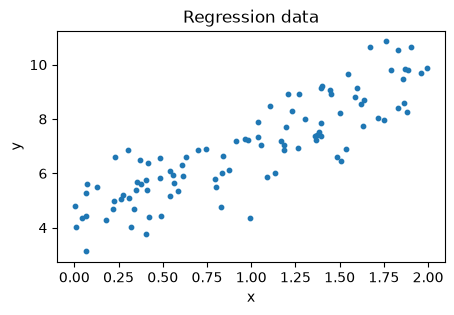

In [5]:
#@title Generate the regression data
torch.manual_seed(0)   # fixed data, even if this cell is re-run on its own
N = 100
X_data = 2 * torch.rand(N)
Y_data = 4 + 3 * X_data + torch.randn(N)

plt.figure(figsize=(5, 3))
plt.scatter(X_data, Y_data, s=10)
plt.xlabel('x'); plt.ylabel('y'); plt.title('Regression data');

In [6]:
def regression_loss(t0, t1, X=X_data, Y=Y_data):
  """Mean squared error of the model  y_hat = t0 + t1 * x  on the samples (X, Y).
  t0 and t1 are either scalar tensors or two grids of the same shape; the output
  must have the same shape as t0 (hint: add a trailing dimension with unsqueeze(-1)
  and average over it)."""
  y_hat = t0.unsqueeze(-1) + t1.unsqueeze(-1) * X   # shape t0.shape + (len(X),)
  return ((y_hat - Y) ** 2).mean(-1)


In [7]:
#@title Sanity check for the test problems
def _check(name, fn, target, tol=1e-4):
  try:
    value = fn()
    ok = value is not None and abs(float(value) - target) < tol
    got = None if value is None else float(value)
  except Exception as e:
    ok, got = False, repr(e)
  print(('[PASS] ' if ok else '[FAIL] ') + f'{name}: got {got}, expected {target}')

t = lambda v: torch.tensor(float(v))
_check('quadratic(1, 0), kappa=10, angle=0 ', lambda: make_quadratic(10, 0)(t(1), t(0)), 0.5)
_check('quadratic(0, 1), kappa=10, angle=0 ', lambda: make_quadratic(10, 0)(t(0), t(1)), 5.0)
_check('quadratic(1, 1), kappa=10, angle=45', lambda: make_quadratic(10, 45)(t(1), t(1)), 1.0)
_check('saddle(0, 1)                        ', lambda: saddle(t(0), t(1)), -0.25)
_check('rosenbrock(1, 1)                    ', lambda: rosenbrock(t(1), t(1)), 0.0)
_check('rosenbrock(0, 0)                    ', lambda: rosenbrock(t(0), t(0)), 1.0)
_A = torch.stack([torch.ones(N), X_data], 1)
_check('regression_loss at (0, 0)           ', lambda: regression_loss(t(0), t(0)), float((Y_data**2).mean()))
try:
  _grid = regression_loss(torch.zeros(3, 4), torch.zeros(3, 4))
  _ok = _grid is not None and _grid.shape == (3, 4)
except Exception:
  _ok = False
print(('[PASS] ' if _ok else '[FAIL] ') + 'regression_loss works on grids')

[PASS] quadratic(1, 0), kappa=10, angle=0 : got 0.5, expected 0.5
[PASS] quadratic(0, 1), kappa=10, angle=0 : got 5.0, expected 5.0
[PASS] quadratic(1, 1), kappa=10, angle=45: got 1.0, expected 1.0
[PASS] saddle(0, 1)                        : got -0.25, expected -0.25
[PASS] rosenbrock(1, 1)                    : got 0.0, expected 0.0
[PASS] rosenbrock(0, 0)                    : got 1.0, expected 1.0
[PASS] regression_loss at (0, 0)           : got 51.209598541259766, expected 51.209598541259766
[PASS] regression_loss works on grids


In [8]:
#@title Helper functions for problems and plotting

# least-squares solution of the regression problem (only used to mark the minimum)
_A = torch.stack([torch.ones(N), X_data], 1)
theta_star = torch.linalg.lstsq(_A, Y_data.unsqueeze(1)).solution.squeeze()
reg_f_star = ((_A @ theta_star - Y_data) ** 2).mean().item()   # computed directly, independent of the code being checked

def get_problem(name, kappa=10., angle=0.):
  """Returns (loss_func, plot bounds (xmin, xmax, ymin, ymax), list of minima, optimal value)."""
  if name == 'quadratic':
    return make_quadratic(kappa, angle), (-2, 2, -2, 2), [(0, 0)], 0.
  if name == 'saddle':
    return saddle, (-1.5, 1.5, -1.6, 1.6), [(0, -1), (0, 1)], -0.25
  if name == 'rosenbrock':
    return rosenbrock, (-2, 2, -1, 3), [(1, 1)], 0.
  if name == 'regression':
    return regression_loss, (1.5, 6.5, 0.5, 5.5), [tuple(theta_star.tolist())], reg_f_star
  raise ValueError(name)

def new_states(*keys, n_params=2):
  """Creates a states dict with one zero-initialized entry per parameter for each key, and a step counter 't'."""
  states = {k: [torch.tensor(0.) for _ in range(n_params)] for k in keys}
  states['t'] = 0
  return states

def gen_2d_loss_surface(loss_func, min_x, max_x, min_y, max_y, n_x=200, n_y=200):
  X, Y = torch.meshgrid(torch.linspace(min_x, max_x, n_x), torch.linspace(min_y, max_y, n_y), indexing='xy')
  with torch.no_grad():
    Z = loss_func(X, Y)
  return X.numpy(), Y.numpy(), Z.numpy()

def make_contour_plot(loss_func, bounds, ax, minima=(), saddles=()):
  X, Y, Z = gen_2d_loss_surface(loss_func, *bounds)
  Zs = Z - Z.min()
  levels = np.unique(np.quantile(Zs, np.linspace(0, 1, 40) ** 2.5))
  ax.contour(X, Y, Zs, levels, alpha=0.5, linewidths=0.8)
  ax.contourf(X, Y, Zs, levels, alpha=0.2)
  for i, m in enumerate(minima):
    ax.plot(*m, 'r*', ms=16, label='minimum' if i == 0 else None)
  for s in saddles:
    ax.plot(*s, 'kX', ms=10, label='saddle point')
  ax.set_xlim(bounds[0], bounds[1]); ax.set_ylim(bounds[2], bounds[3])
  ax.set_xlabel(r'x ($\theta_0$)'); ax.set_ylabel(r'y ($\theta_1$)')

COLORS = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:olive']

def plot_trajectories(problem, results, title='', arrows=None, loss_plot=True, updates_per_epoch=None):
  """problem: output of get_problem.  results: dict name -> (trajectory, losses) returned by the runners.
  updates_per_epoch: optional dict name -> number of updates per epoch; if given, the loss plot uses epochs on the x-axis."""
  loss_func, bounds, minima, f_star = problem
  saddles = [(0, 0)] if loss_func is saddle else []
  if loss_plot:
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1.3, 1]})
  else:
    fig, ax = plt.subplots(figsize=(8, 5))
  make_contour_plot(loss_func, bounds, ax, minima, saddles)
  if arrows is None:
    arrows = len(results) == 1 and len(next(iter(results.values()))[0]) <= 150
  for k, (name, (traj, losses)) in enumerate(results.items()):
    c = COLORS[k % len(COLORS)]
    if arrows:
      for i in range(len(traj) - 1):
        ax.annotate('', xy=traj[i + 1], xytext=traj[i],
                    arrowprops={'arrowstyle': '->', 'color': c, 'lw': 1})
      ax.plot([], [], color=c, label=name)
    else:
      ms = 2 if len(traj) > 300 else 3
      ax.plot(traj[:, 0], traj[:, 1], '-o', color=c, ms=ms, lw=0.8, alpha=0.8, label=name)
    ax.plot(*traj[-1], 's', color=c, ms=8, mec='k')
  first = next(iter(results.values()))[0][0]
  ax.plot(*first, 'b*', ms=16, label='start')
  ax.legend(fontsize=8, loc='best'); ax.set_title(title)
  if loss_plot:
    for k, (name, (traj, losses)) in enumerate(results.items()):
      c = COLORS[k % len(COLORS)]
      gap = np.clip(np.asarray(losses) - f_star, 1e-12, None)
      x = np.arange(len(gap)) / (updates_per_epoch[name] if updates_per_epoch else 1)
      if len(gap) > 300:   # long noisy curve: show it faintly, plus a moving average (in log space)
        w = max(len(gap) // 50, 2)
        smooth = np.exp(np.convolve(np.log(gap), np.ones(w) / w, mode='valid'))
        ax2.semilogy(x, gap, color=c, lw=0.5, alpha=0.25)
        ax2.semilogy(x[w - 1:], smooth, color=c, lw=1.8, label=name + ' (moving avg.)')
      else:
        ax2.semilogy(x, gap, color=c, label=name, lw=1.2)
    ax2.set_xlabel('epoch' if updates_per_epoch else 'update step'); ax2.set_ylabel(r'$f - f^*$ (log scale)')
    ax2.set_title('distance to the optimal value'); ax2.legend(fontsize=8); ax2.grid(alpha=0.3)
  plt.tight_layout(); plt.show()

### Plotting the test problems

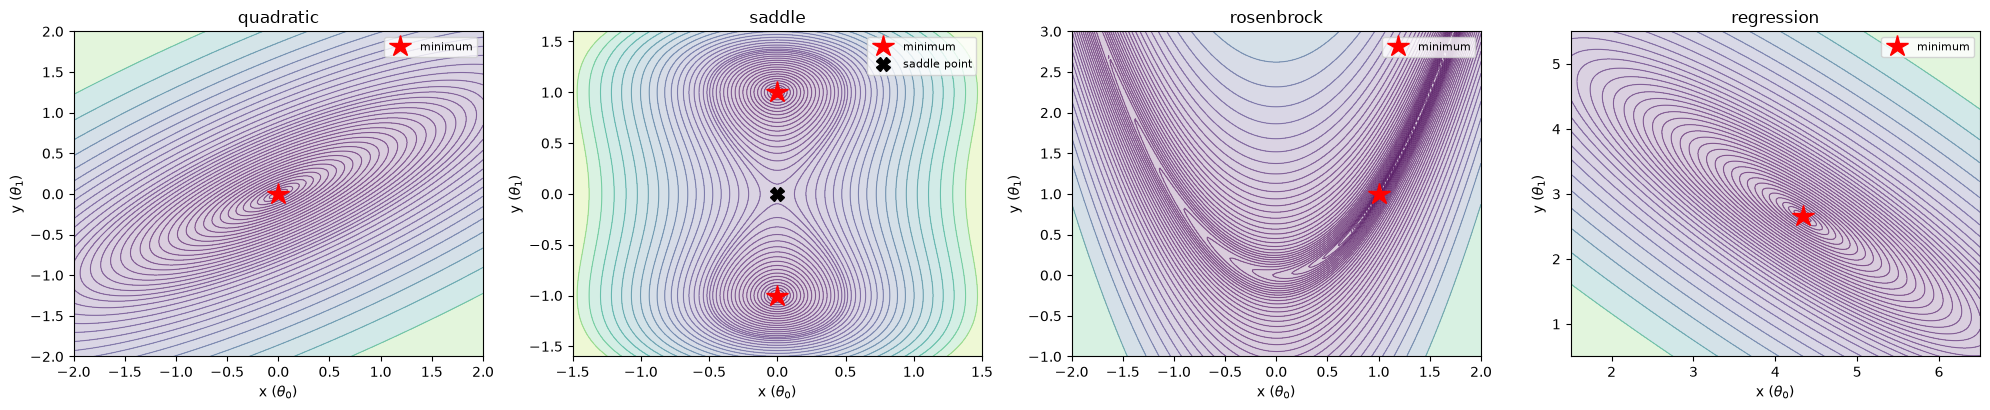

In [9]:
kappa = 10
angle = 30

fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
for ax, name in zip(axes, ['quadratic', 'saddle', 'rosenbrock', 'regression']):
  f, bounds, minima, _ = get_problem(name, kappa, angle)
  make_contour_plot(f, bounds, ax, minima, [(0, 0)] if name == 'saddle' else [])
  ax.set_title(name); ax.legend(fontsize=8)
plt.tight_layout()

### Gradients and the Hessian
Every method needs $\nabla f$, and Newton's method also needs the Hessian $\mathbf H = \nabla^2 f$. We compute both with `torch.autograd`.

* `compute_grads` returns the gradients of `loss` with respect to each tensor in `params` (`torch.autograd.grad`).
* `compute_grads_and_hessian` also returns the $2\times2$ Hessian. It computes the gradients with `create_graph=True` and differentiates each component again. Some second derivatives do not depend on a parameter at all (for the saddle, $\partial^2 f/\partial x\partial y = 0$), so it passes `allow_unused=True` and treats `None` as zero.

In [10]:
def compute_grads(loss, params):
  grads = list(torch.autograd.grad(loss, params))
  return grads


def compute_grads_and_hessian(loss, params):
  n = len(params)
  hessian = torch.zeros(n, n)
  first = torch.autograd.grad(loss, params, create_graph=True)
  for i in range(n):
    if not first[i].requires_grad:   # this gradient component is a constant: its row of H is zero
      continue
    row = torch.autograd.grad(first[i], params, retain_graph=True, allow_unused=True)
    for j in range(n):
      if row[j] is not None:
        hessian[i, j] = row[j].detach()
  grads = [g.detach() for g in first]
  return grads, hessian

In [11]:
#@title Sanity check for gradients and Hessian
def _check_grad(name, fn):
  try:
    ok = bool(fn())
  except Exception:
    ok = False
  print(('[PASS] ' if ok else '[FAIL] ') + name)

def _grad_rosen():
  p = [torch.tensor(0., requires_grad=True), torch.tensor(0., requires_grad=True)]
  g = compute_grads(rosenbrock(*p), p)
  return g is not None and torch.allclose(torch.stack(g), torch.tensor([-2., 0.]))

def _hess(f, point, target):
  p = [torch.tensor(v, requires_grad=True) for v in point]
  g, H = compute_grads_and_hessian(f(*p), p)
  return g is not None and torch.allclose(H, torch.tensor(target), atol=1e-4)

_check_grad('gradient of rosenbrock at (0, 0) = (-2, 0)', _grad_rosen)
_check_grad('Hessian of the rotated quadratic equals A', lambda: _hess(make_quadratic(10, 45), (0.3, -0.7), [[5.5, -4.5], [-4.5, 5.5]]))
_check_grad('Hessian of saddle at (0.5, 0.5)', lambda: _hess(saddle, (0.5, 0.5), [[2., 0.], [0., -0.25]]))

[PASS] gradient of rosenbrock at (0, 0) = (-2, 0)
[PASS] Hessian of the rotated quadratic equals A
[PASS] Hessian of saddle at (0.5, 0.5)


In [12]:
#@title Optimizer runner and checker
def run_optimizer(loss_func, update_func, start, hyper_params, states=None, epochs=100, noise_std=0.):
  """Runs `epochs` full-batch update steps from `start`.
  noise_std: std of Gaussian noise added to
  every gradient (a crude imitation of stochastic gradients).
  Returns (trajectory as array of shape (steps+1, 2), array of losses along the trajectory)."""
  params = [torch.tensor(float(v), requires_grad=True) for v in start]
  states = {} if states is None else states
  hyper_params = dict(hyper_params)
  traj, losses = [[p.item() for p in params]], []
  for t in range(epochs):
    loss = loss_func(*params)
    losses.append(loss.item())
    grads = compute_grads(loss, params)
    if noise_std > 0:
      grads = [g + noise_std * torch.randn(()) for g in grads]
    with torch.no_grad():
      update_func(params, grads, states, hyper_params)
    traj.append([p.item() for p in params])
    if not np.all(np.isfinite(traj[-1])) or np.max(np.abs(traj[-1])) > 1e4:
      print(f'Warning: {getattr(update_func, "__name__", "optimizer")} diverged at step {t + 1}')
      traj = traj[:-1]
      break
  with torch.no_grad():
    losses.append(loss_func(*[torch.tensor(v) for v in traj[-1]]).item())
  return np.array(traj), np.array(losses[:len(traj)])


def check_update(update_func, torch_opt, torch_kwargs, hyper_params, states, steps=30, start=(-1.2, 1.0)):
  """Compares an update rule with PyTorch's implementation on the Rosenbrock function."""
  mine = [torch.tensor(v, requires_grad=True) for v in start]
  ref = [torch.tensor(v, requires_grad=True) for v in start]
  opt = torch_opt(ref, **torch_kwargs)
  try:
    for _ in range(steps):
      grads = compute_grads(rosenbrock(*mine), mine)
      with torch.no_grad():
        update_func(mine, grads, states, dict(hyper_params))
      opt.zero_grad(); rosenbrock(*ref).backward(); opt.step()
    ok = torch.allclose(torch.stack(mine), torch.stack(ref), rtol=1e-4, atol=1e-5)
  except Exception as e:
    print('[FAIL] error:', repr(e)); return
  print(('[PASS] ' if ok else '[FAIL] ') + f'{update_func.__name__}: after {steps} steps mine = {torch.stack(mine).detach().numpy()}, '
        f'torch = {torch.stack(ref).detach().numpy()}')

## 1. Gradient descent

$$\mathbf{w} \leftarrow \mathbf{w} - \eta\, \nabla_{\mathbf w} f(\mathbf w)$$

The same learning rate $\eta$ is applied to every component.

In [13]:
def GD_update(params, grads, states, hyper_params):
  # hyper-param typical values: lr=0.01
  # GD doesn't have any state
  lr = hyper_params['lr']
  for param, grad in zip(params, grads):
    param -= lr * grad


In [14]:
check_update(GD_update, torch.optim.SGD, {'lr': 1e-3}, {'lr': 1e-3}, new_states())

[PASS] GD_update: after 30 steps mine = [-1.0056434  1.0193127], torch = [-1.0056434  1.0193127]


### 1.1 How large can $\eta$ be?
For a quadratic with curvature $a$ along some direction, the optimal step along that direction is $\eta_{opt} = 1/a$. Gradient descent

* converges monotonically for $\eta < \eta_{opt}$,
* oscillates but converges for $\eta_{opt} < \eta < 2\eta_{opt}$,
* **diverges** for $\eta > 2\eta_{opt}$.

With a single $\eta$ for all directions, the steepest direction (largest eigenvalue of $\mathbf A$) decides whether we diverge, while the flattest direction decides how slow we are.

The steepest direction has curvature $\kappa$, so its optimal step is $\eta_{opt} = 1/\kappa$. Below I run GD with `lr_factor` = 0.5, 1.0, 1.5, 1.95 and 2.05 (learning rate `lr_factor * eta_opt`), for $\kappa = 10$ and $\kappa = 50$.

lr = 0.1500, final loss = 3.656e-06


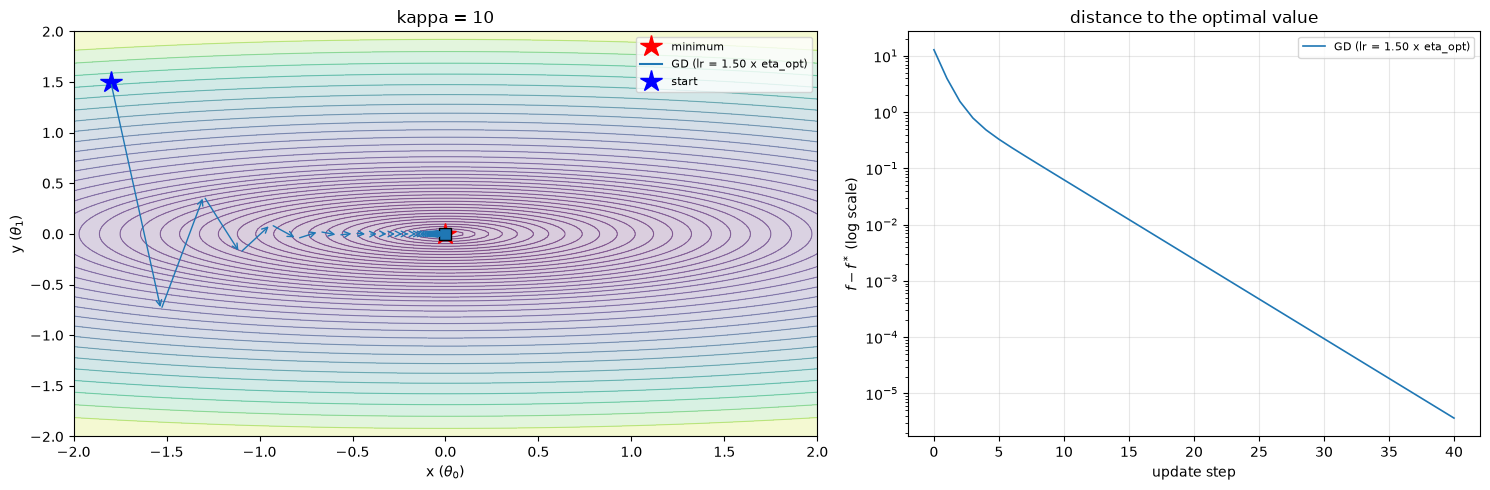

In [15]:
kappa = 10
angle = 0
lr_factor = 1.5
start_x = -1.8
start_y = 1.5
epochs = 40

eta_opt = 1. / kappa   # steepest direction: largest eigenvalue of A is kappa

problem = get_problem('quadratic', kappa, angle)
traj, losses = run_optimizer(problem[0], GD_update, (start_x, start_y), {'lr': lr_factor * eta_opt}, epochs=epochs)
print(f'lr = {lr_factor * eta_opt:.4f}, final loss = {losses[-1]:.3e}')
plot_trajectories(problem, {f'GD (lr = {lr_factor:.2f} x eta_opt)': (traj, losses)}, title=f'kappa = {kappa}')

In [16]:
#@title Extra runs for Section 1.1 (every lr_factor, kappa = 10 and 50)
for kappa_ in [10, 50]:
  f_ = get_problem('quadratic', kappa_, 0)[0]
  print(f'kappa = {kappa_}')
  for fac in [0.5, 1.0, 1.5, 1.95, 2.05]:
    tr_, ls_ = run_optimizer(f_, GD_update, (-1.8, 1.5), {'lr': fac / kappa_}, epochs=40)
    print(f'  lr_factor = {fac:4.2f}: y after steps 1-3 = {np.round(tr_[1:4, 1], 3)},  '
          f'final (x, y) = ({tr_[-1, 0]:+.4f}, {tr_[-1, 1]:+.4f}),  final loss = {ls_[-1]:.2e}')

kappa = 10
  lr_factor = 0.50: y after steps 1-3 = [0.75  0.375 0.188],  final (x, y) = (-0.2313, +0.0000),  final loss = 2.68e-02
  lr_factor = 1.00: y after steps 1-3 = [0. 0. 0.],  final (x, y) = (-0.0266, +0.0000),  final loss = 3.54e-04
  lr_factor = 1.50: y after steps 1-3 = [-0.75   0.375 -0.188],  final (x, y) = (-0.0027, +0.0000),  final loss = 3.66e-06
  lr_factor = 1.95: y after steps 1-3 = [-1.425  1.354 -1.286],  final (x, y) = (-0.0003, +0.1928),  final loss = 1.86e-01
  lr_factor = 2.05: y after steps 1-3 = [-1.575  1.654 -1.736],  final (x, y) = (-0.0002, +10.5600),  final loss = 5.58e+02
kappa = 50
  lr_factor = 0.50: y after steps 1-3 = [0.75  0.375 0.188],  final (x, y) = (-1.2041, +0.0000),  final loss = 7.25e-01
  lr_factor = 1.00: y after steps 1-3 = [0. 0. 0.],  final (x, y) = (-0.8023, +0.0000),  final loss = 3.22e-01
  lr_factor = 1.50: y after steps 1-3 = [-0.75   0.375 -0.188],  final (x, y) = (-0.5323, +0.0000),  final loss = 1.42e-01
  lr_factor = 1.95: y a

> Why is the flat direction so slow? With `lr_factor = 1` and $\kappa = 50$, the steep direction is solved in one step, but the flat direction is still far from optimal after 40 steps.

With `lr_factor = 1` and `kappa = 50` the learning rate is $\eta = 1/50 = 0.02$. Along the steep direction ($y$, curvature 50) GD multiplies the error by $1 - 50\eta = 0$ per step, so $y$ is exactly 0 after one step. Along the flat direction ($x$, curvature 1) the factor is $1 - \eta = 0.98$, so after 40 steps $x = -1.8 \cdot 0.98^{40} = -0.80$ and the loss is still 0.32.

The optimal step for the flat direction is $\eta_{opt,\max} = 1/1$ and for the steep one $\eta_{opt,\min} = 1/\kappa$, so their ratio is exactly $\kappa$. A single $\eta$ must stay below $2/\kappa$ to keep the steep direction stable, and with such an $\eta$ the flat direction shrinks only by about $1 - 1/\kappa$ per step. It needs about $\kappa$ steps to shrink its error by a factor of $e$, so the number of steps grows linearly with the condition number. With `lr_factor = 1`, the same 40 steps left a loss of $3.5\cdot10^{-4}$ for $\kappa = 10$ and 0.32 for $\kappa = 50$.

If we increase $\eta$ to speed up the flat direction, the steep direction breaks first. Above $\eta_{opt}$ it oscillates, and above $2\eta_{opt}$ it diverges. With `lr_factor = 2.05` its factor is $|1 - 2.05| = 1.05$, so $y$ grew from 1.5 to $1.5 \cdot 1.05^{40} = 10.56$ and the loss to $2.8\cdot10^3$, while $x$ had only reached $-0.34$.

What each `lr_factor` did for $\kappa = 10$ (table above):
* 0.5: $y$ halves every step and keeps its sign (0.75, 0.375, 0.19). Final loss $2.7\cdot10^{-2}$, limited by the slow $x$.
* 1.0: $y = 0$ after the first step. Final loss $3.5\cdot10^{-4}$.
* 1.5: $y$ flips sign and halves ($-0.75$, 0.375, $-0.19$), so it converges while oscillating. This gave the lowest final loss, $3.7\cdot10^{-6}$, because the larger $\eta$ also speeds up $x$ (factor 0.85 instead of 0.9).
* 1.95: $y$ oscillates with factor 0.95 and is still 0.19 after 40 steps. The loss is 0.19 although $x$ is almost solved.
* 2.05: $y$ grows by 1.05 per step and GD diverges (loss 558).

With $\kappa = 50$ the $y$ column is identical, because it only depends on `lr_factor`, but $x$ is much slower: the best final loss was 0.14 (at 1.5) instead of $3.7\cdot10^{-6}$.

## 2. Newton's method (second order)

Newton's method uses the Hessian to rescale (and rotate) the gradient:
$$\mathbf w \leftarrow \mathbf w - \eta\, \mathbf H^{-1} \nabla_{\mathbf w} f(\mathbf w)$$
For a quadratic, $\mathbf H = \mathbf A$. With $\eta = 1$ it jumps to the minimum in **one step**, whatever the condition number or rotation.

`newton_method` is a whole optimizer, not one update step. At every step it:
1. creates the current parameters as two fresh scalar tensors that require gradients, so nothing accumulates across steps;
2. computes the loss, its gradient and its Hessian with `compute_grads_and_hessian`;
3. finds the Newton direction $\mathbf d$ by solving $\mathbf H\,\mathbf d = \nabla f$ with `torch.linalg.solve`, without forming $\mathbf H^{-1}$;
4. updates $\mathbf w \leftarrow \mathbf w - \eta\,\mathbf d$ outside the autograd graph and records the new point and its loss.

In [17]:
def newton_method(loss_func, start, lr=1., epochs=10, noise_std=0.):
  """Runs `epochs` steps of Newton's method on loss_func(x, y), starting from start = (x0, y0).

  noise_std: if > 0, add Gaussian noise `noise_std * torch.randn(())` to each component
             of the gradient before computing the step (used in Section 5.2).
  Returns (same format as the other optimizers, so the plotting helpers work):
    traj:   numpy array of shape (epochs + 1, 2) with the starting point and the point after every step
    losses: numpy array of shape (epochs + 1,) with the loss at every point of traj
  """
  point = [float(v) for v in start]
  traj, losses = [list(point)], []
  for t in range(epochs):
    # 1. fresh leaf tensors at the current point, so nothing accumulates across steps
    params = [torch.tensor(v, requires_grad=True) for v in point]
    # 2. loss, gradient and Hessian
    loss = loss_func(*params)
    losses.append(loss.item())
    grads, H = compute_grads_and_hessian(loss, params)
    if noise_std > 0:
      grads = [g + noise_std * torch.randn(()) for g in grads]
    # 3. Newton direction: solve H d = grad
    d = torch.linalg.solve(H, torch.stack(grads))
    # 4. update and record the new point
    point = [p - lr * di for p, di in zip(point, d.tolist())]
    traj.append(list(point))
    if not np.all(np.isfinite(point)) or np.max(np.abs(point)) > 1e4:
      print(f'Warning: newton_method diverged at step {t + 1}')
      traj = traj[:-1]
      break
  with torch.no_grad():
    losses.append(loss_func(*[torch.tensor(v) for v in traj[-1]]).item())
  return np.array(traj), np.array(losses)

In [18]:
#@title Sanity check for newton_method
def _newton_checks():
  f = make_quadratic(30, 30)
  traj, losses = newton_method(f, (-1.8, 1.5), lr=1., epochs=3)
  yield 'returns arrays of shapes (epochs + 1, 2) and (epochs + 1,)', traj.shape == (4, 2) and losses.shape == (4,)
  yield 'traj[0] is the start point and losses[0] = f(start)', np.allclose(traj[0], [-1.8, 1.5]) and abs(losses[0] - f(torch.tensor(-1.8), torch.tensor(1.5)).item()) < 1e-4
  yield 'quadratic with lr = 1: minimum (0, 0) reached after one step', np.allclose(traj[1], [0., 0.], atol=1e-4)
  traj, losses = newton_method(f, (-1.8, 1.5), lr=0.5, epochs=1)
  yield 'quadratic with lr = 0.5: one step goes exactly half way', np.allclose(traj[1], [-0.9, 0.75], atol=1e-4)
  traj, losses = newton_method(rosenbrock, (-1.5, 2.5), lr=1., epochs=10)
  yield 'rosenbrock: reaches (1, 1) within 10 steps', np.allclose(traj[-1], [1., 1.], atol=1e-3)

try:
  for name, ok in _newton_checks():
    print(('[PASS] ' if ok else '[FAIL] ') + name)
except Exception as e:
  print('[FAIL] error:', repr(e))

[PASS] returns arrays of shapes (epochs + 1, 2) and (epochs + 1,)
[PASS] traj[0] is the start point and losses[0] = f(start)
[PASS] quadratic with lr = 1: minimum (0, 0) reached after one step
[PASS] quadratic with lr = 0.5: one step goes exactly half way
[PASS] rosenbrock: reaches (1, 1) within 10 steps


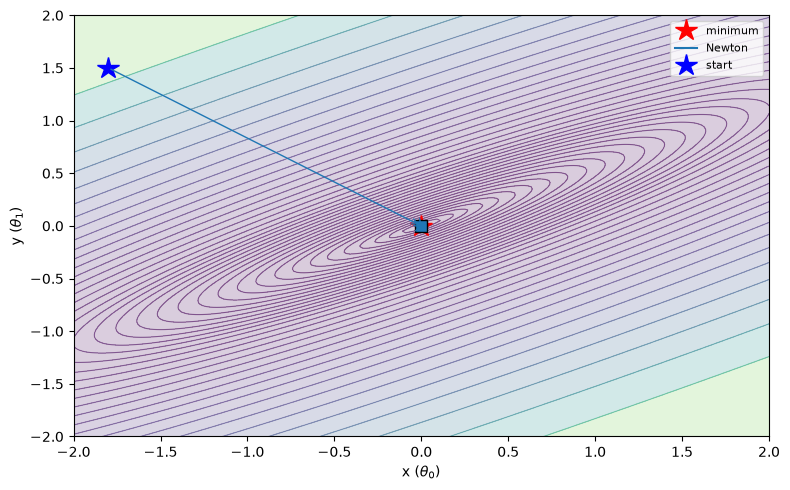

In [19]:
kappa = 30
angle = 30
learning_rate = 1.0
epochs = 5

problem = get_problem('quadratic', kappa, angle)
traj, losses = newton_method(problem[0], (-1.8, 1.5), lr=learning_rate, epochs=epochs)
plot_trajectories(problem, {'Newton': (traj, losses)}, loss_plot=False)

### 2.1 Newton near a saddle point
Newton's method and GD start from the same point on the saddle function, with `start_y` from 0.3 to 0.9.

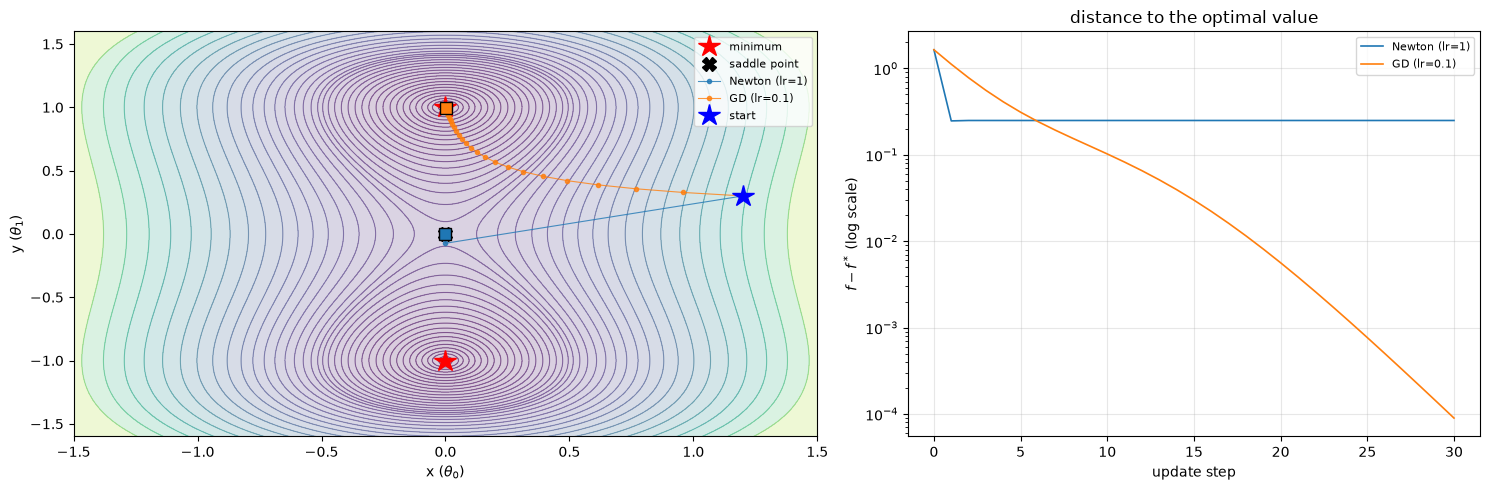

In [20]:
start_x = 1.2
start_y = 0.3
epochs = 30

problem = get_problem('saddle')
res = {
  'Newton (lr=1)': newton_method(saddle, (start_x, start_y), lr=1., epochs=epochs),
  'GD (lr=0.1)': run_optimizer(saddle, GD_update, (start_x, start_y), {'lr': 0.1}, epochs=epochs),
}
plot_trajectories(problem, res, arrows=False)

In [21]:
#@title Extra runs for Section 2.1 (end points after 30 steps for several start_y)
print('start_y |  Newton end      |  GD end          | Newton y after steps 1-3')
for sy in [0.0, 0.3, 0.4, 0.5, 0.577, 0.6, 0.7, 0.8, 0.9]:
  tn_, _ = newton_method(saddle, (1.2, sy), lr=1., epochs=30)
  tg_, _ = run_optimizer(saddle, GD_update, (1.2, sy), {'lr': 0.1}, epochs=30)
  print(f'{sy:7.3f} | ({tn_[-1, 0]:+.3f}, {tn_[-1, 1]:+.3f}) | ({tg_[-1, 0]:+.3f}, {tg_[-1, 1]:+.3f}) | {np.round(tn_[1:4, 1], 2)}')

start_y |  Newton end      |  GD end          | Newton y after steps 1-3
  0.000 | (+0.000, +0.000) | (+0.001, +0.000) | [0. 0. 0.]
  0.300 | (+0.000, +0.000) | (+0.001, +0.991) | [-0.07  0.   -0.  ]
  0.400 | (+0.000, +0.000) | (+0.001, +0.996) | [-0.25  0.04 -0.  ]
  0.500 | (+0.000, -1.000) | (+0.001, +0.998) | [-1. -1. -1.]
  0.577 | (+0.000, -1.000) | (+0.001, +0.998) | [-316.75 -211.17 -140.78]
  0.600 | (+0.000, +1.000) | (+0.001, +0.999) | [5.4  3.64 2.49]
  0.700 | (+0.000, +1.000) | (+0.001, +0.999) | [1.46 1.15 1.03]
  0.800 | (+0.000, +1.000) | (+0.001, +1.000) | [1.11 1.02 1.  ]
  0.900 | (+0.000, +1.000) | (+0.001, +1.000) | [1.02 1.   1.  ]


> Newton converged in very few steps on the quadratic. Why is it still not used to train neural networks with millions of parameters?

1. **Cost.** With $n$ parameters the Hessian has $n^2$ entries, and solving $\mathbf H\mathbf d = \nabla f$ costs $O(n^3)$. For $n = 10^7$ the Hessian alone would hold $10^{14}$ numbers (400 TB in float32), and one step would need about $10^{21}$ operations. With $n = 2$ in this notebook the cost is invisible.
2. **Saddle points.** Neural-network losses are non-convex and have very many saddle points, and Newton's method is attracted to them. It looks for a point where the gradient is zero, and a saddle is such a point. In Section 2.1 Newton started from $y = 0.3$ and $0.4$ and converged to the saddle $(0, 0)$, while GD went to the minimum $(0, 1)$. Where the curvature is close to zero the step $\mathbf H^{-1}\nabla f$ also explodes: from $y = 0.577 \approx 1/\sqrt3$ the first Newton step went to $y = -317$.

> In the saddle experiment GD and Newton start from the same points but do not always end in the same place. Why? What happens to GD from `start_y = 0`, and why are saddle points a bigger problem for Newton than for GD?

GD's step is $-\eta\nabla f$, so it always moves downhill. Near the saddle $\partial f/\partial y = y^3 - y \approx -y$, so the step pushes $y$ away from 0. Because the curvature along $y$ is negative, $|y|$ grows by a factor of about $1 + \eta$ per step. GD therefore rolls down to the minimum on the side where it started: from every $y_0 > 0$ in my table it ended at $(0, 0.99)$ to $(0, 1.00)$.

Newton's step jumps to the stationary point of the local quadratic model. Along $y$ the step is $-g_y/H_{yy}$ with $H_{yy} = 3y^2 - 1$. For $|y| < 1/\sqrt3$ the curvature is negative, the division flips the sign of the step, and Newton moves uphill in $y$, toward the maximum of the model along $y$. Along $x$ the curvature is positive, so the stationary point of the model is the saddle. Without noise the update is $y_{new} = 2y^3/(3y^2 - 1)$, and $|y_{new}| < |y|$ whenever $|y| < 1/\sqrt5 \approx 0.45$. In my runs:
* $y_0 = 0.3$ and $0.4$: Newton converged to the saddle $(0, 0)$.
* $y_0 = 0.5$: the first step happened to land exactly on $y = -1$, the minimum on the other side.
* $y_0 = 0.577$ ($H_{yy} \approx 0$): the first step went to $y = -317$, and Newton then crawled back toward $-1$.
* $y_0 \ge 0.6$: the curvature is positive and Newton reached $(0, 1)$ in 3 to 5 steps, faster than GD.

With `start_y = 0`, $\partial f/\partial y$ is exactly 0 on the whole line $y = 0$, so GD never gets a push in $y$. It only solves the $x$ part and converges to the saddle $(0, 0)$. For GD the saddle is an unstable equilibrium: any tiny $y \neq 0$ would grow.

This is why saddles are a much bigger problem for Newton's method. GD gets stuck only if it starts exactly on the saddle's stable set (here the line $y = 0$), which has zero volume, and any perturbation grows. For Newton the saddle is an attracting fixed point, and every start in the band $|y| < 0.45$ converges to it. In high dimensions saddle points are far more common than minima, so Newton would end up at one most of the time.

## 3. Momentum methods

### 3.1 Momentum
Gradient descent zig-zags across narrow valleys and crawls along their flat bottoms. Momentum keeps an exponentially decaying sum of past gradients (each scaled by $\eta$), so oscillating components cancel out and consistent components add up:
$$\Delta\mathbf w \leftarrow \beta\,\Delta\mathbf w - \eta\,\nabla f(\mathbf w), \qquad \mathbf w \leftarrow \mathbf w + \Delta\mathbf w$$

### 3.2 Nesterov's accelerated gradient
Nesterov first moves along the old momentum, then computes the gradient at that *look-ahead* point:
$$\Delta\mathbf w \leftarrow \beta\,\Delta\mathbf w - \eta\,\nabla f(\mathbf w + \beta\,\Delta\mathbf w), \qquad \mathbf w \leftarrow \mathbf w + \Delta\mathbf w$$
Our update functions only receive the gradient at the current point. Luckily, if we keep track of the look-ahead point $\tilde{\mathbf w} = \mathbf w + \beta\Delta\mathbf w$ instead of $\mathbf w$, the same algorithm can be written as
$$\Delta\mathbf w \leftarrow \beta\,\Delta\mathbf w - \eta\,\nabla f(\tilde{\mathbf w}), \qquad \tilde{\mathbf w} \leftarrow \tilde{\mathbf w} + \beta\,\Delta\mathbf w - \eta\,\nabla f(\tilde{\mathbf w})$$
(this is also how PyTorch implements it). Use this form.

In [22]:
def momentum_update(params, grads, states, hyper_params):
  # hyper-param typical values: lr=0.01, beta=0.9
  # states['delta'][i] is Delta w for params[i]
  lr, beta = hyper_params['lr'], hyper_params['beta']
  for i, (param, grad) in enumerate(zip(params, grads)):
    states['delta'][i] = beta * states['delta'][i] - lr * grad
    param += states['delta'][i]


def nesterov_update(params, grads, states, hyper_params):
  # hyper-param typical values: lr=0.01, beta=0.9
  lr, beta = hyper_params['lr'], hyper_params['beta']
  for i, (param, grad) in enumerate(zip(params, grads)):
    # params hold the look-ahead point w~ and grad is the gradient there
    states['delta'][i] = beta * states['delta'][i] - lr * grad
    param += beta * states['delta'][i] - lr * grad


In [23]:
check_update(momentum_update, torch.optim.SGD, {'lr': 1e-3, 'momentum': 0.9}, {'lr': 1e-3, 'beta': 0.9}, new_states('delta'))
check_update(nesterov_update, torch.optim.SGD, {'lr': 1e-3, 'momentum': 0.9, 'nesterov': True}, {'lr': 1e-3, 'beta': 0.9}, new_states('delta'))

[PASS] momentum_update: after 30 steps mine = [-0.29661047  0.01358199], torch = [-0.2966107   0.01358215]
[PASS] nesterov_update: after 30 steps mine = [-0.635684    0.41154316], torch = [-0.635684   0.4115431]


GD, momentum and Nesterov on the ill-conditioned quadratic ($\kappa=30$, rotated by $30°$) and on the long valley, with $\beta \in \{0, 0.5, 0.9, 0.99\}$. The long valley uses a learning rate of $0.0005$ and more epochs.

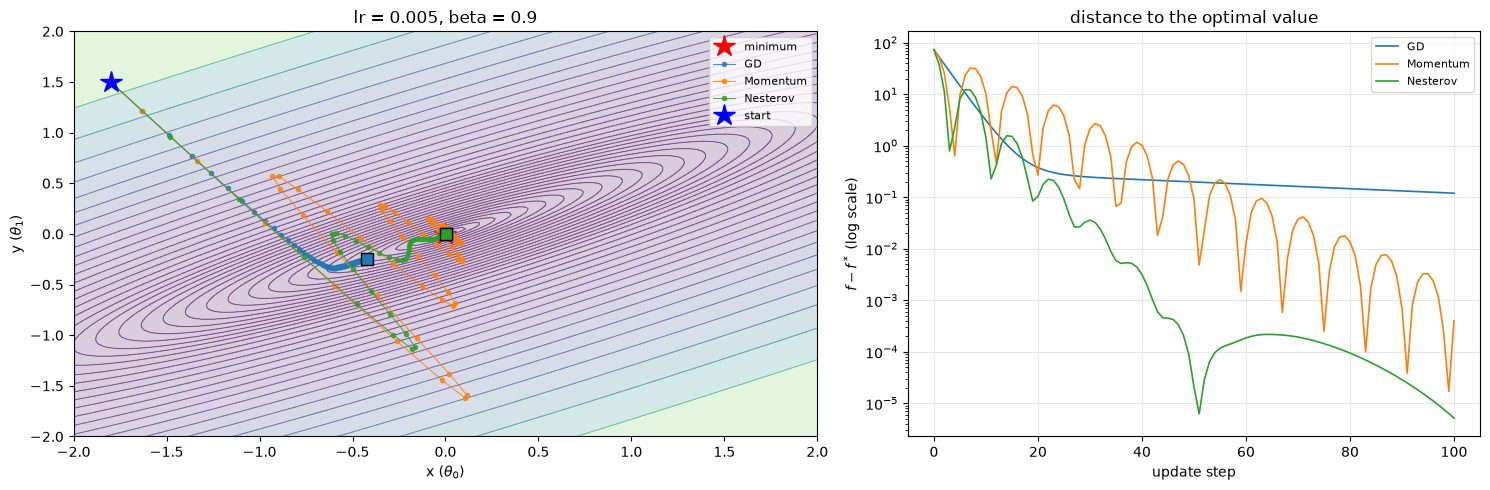

In [24]:
problem_name = "quadratic"  # options: "quadratic", "rosenbrock"
learning_rate = 0.005
beta = 0.9
epochs = 100

problem = get_problem(problem_name, kappa=30, angle=30)
start = (-1.8, 1.5) if problem_name == 'quadratic' else (-1.5, 2.5)
hp = {'lr': learning_rate, 'beta': beta}
res = {
  'GD': run_optimizer(problem[0], GD_update, start, hp, epochs=epochs),
  'Momentum': run_optimizer(problem[0], momentum_update, start, hp, new_states('delta'), epochs=epochs),
  'Nesterov': run_optimizer(problem[0], nesterov_update, start, hp, new_states('delta'), epochs=epochs),
}
plot_trajectories(problem, res, title=f'lr = {learning_rate}, beta = {beta}')

In [25]:
#@title Extra runs for Section 3 (beta sweep)
def _steps_to(losses, f_star, tol=1e-3):
  hit = np.where(np.asarray(losses) - f_star < tol)[0]
  return int(hit[0]) if len(hit) else None

for pname, lr_, ep_ in [('quadratic', 0.005, 100), ('rosenbrock', 0.0005, 1000)]:
  pr_ = get_problem(pname, kappa=30, angle=30)
  st_ = (-1.8, 1.5) if pname == 'quadratic' else (-1.5, 2.5)
  _, lg_ = run_optimizer(pr_[0], GD_update, st_, {'lr': lr_}, epochs=ep_)
  print(f'{pname}, lr = {lr_}, {ep_} steps. GD: final f - f* = {lg_[-1] - pr_[3]:.1e}')
  print('  (final f - f* / steps to reach f - f* < 1e-3 / number of times x crossed the minimum)')
  for b_ in [0, 0.5, 0.9, 0.99]:
    row = []
    for name, fn in [('Momentum', momentum_update), ('Nesterov', nesterov_update)]:
      tr_, ls_ = run_optimizer(pr_[0], fn, st_, {'lr': lr_, 'beta': b_}, new_states('delta'), epochs=ep_)
      cross = int(np.sum(np.diff(np.sign(tr_[:, 0] - pr_[2][0][0])) != 0))
      row.append(f'{name} {ls_[-1] - pr_[3]:.1e} / {_steps_to(ls_, pr_[3])} / {cross}')
    print(f'  beta = {b_:<4}: ' + '  |  '.join(row))

quadratic, lr = 0.005, 100 steps. GD: final f - f* = 1.2e-01
  (final f - f* / steps to reach f - f* < 1e-3 / number of times x crossed the minimum)
  beta = 0   : Momentum 1.2e-01 / None / 0  |  Nesterov 1.2e-01 / None / 0
  beta = 0.5 : Momentum 4.4e-02 / None / 0  |  Nesterov 4.4e-02 / None / 0
  beta = 0.9 : Momentum 4.0e-04 / 67 / 13  |  Nesterov 5.2e-06 / 43 / 1
  beta = 0.99: Momentum 7.0e-02 / None / 12  |  Nesterov 3.7e-02 / 66 / 4


rosenbrock, lr = 0.0005, 1000 steps. GD: final f - f* = 5.3e+00
  (final f - f* / steps to reach f - f* < 1e-3 / number of times x crossed the minimum)


  beta = 0   : Momentum 5.3e+00 / None / 0  |  Nesterov 5.3e+00 / None / 0


  beta = 0.5 : Momentum 3.9e+00 / None / 0  |  Nesterov 3.9e+00 / None / 0


  beta = 0.9 : Momentum 7.5e-03 / None / 0  |  Nesterov 7.8e-03 / None / 0


  beta = 0.99: Momentum 2.3e-04 / 363 / 6  |  Nesterov 2.3e-04 / 127 / 4


> (a) Why does momentum reduce the zig-zag across the valley but speed up the motion along it?
> (b) Why does a large $\beta$ (0.99) overshoot and spiral around the minimum of the quadratic?
> (c) When did Nesterov behave differently from classical momentum?

**(a)** Unrolling the update gives $\Delta\mathbf w_t = -\eta\sum_{k\ge0}\beta^k\,\nabla f(\mathbf w_{t-k})$. Across a narrow valley the gradient component changes sign every step (that is the zig-zag), so neighbouring terms of the sum cancel and the velocity across the valley stays small. Along the valley floor the component has the same sign every step, so the terms add up to about $\eta/(1-\beta)$ times the gradient, which is 10 GD steps for $\beta = 0.9$. On the quadratic (lr 0.005, 100 steps) GD was still at $f = 0.12$ while momentum with $\beta = 0.9$ reached $4\cdot10^{-4}$. On Rosenbrock (lr 0.0005, 1000 steps) GD stopped at 5.3 and momentum with $\beta = 0.9$ reached $7.5\cdot10^{-3}$.

**(b)** With $\beta = 0.99$ only 1% of the velocity is lost per step, and the sum remembers about 100 past gradients. When the iterate reaches the minimum it still carries a large velocity and overshoots. The gradient on the other side points back, but it needs many steps to cancel the stored velocity, so the method behaves like a ball on a spring with almost no friction and circles around the minimum. In my run $x$ crossed the minimum 12 times in 100 steps, and the final loss (0.07) was much worse than with $\beta = 0.9$ ($4\cdot10^{-4}$).

**(c)** Nesterov differed from momentum only when $\beta$ was large. For $\beta = 0$ and $0.5$ the two gave the same numbers. On the quadratic with $\beta = 0.9$, Nesterov reached $f < 10^{-3}$ in 43 steps instead of 67 and crossed the minimum once instead of 13 times. With $\beta = 0.99$ it crossed 4 times instead of 12. On Rosenbrock with $\beta = 0.99$ it reached $10^{-3}$ in 127 steps instead of 363. Nesterov takes the gradient at the look-ahead point $\mathbf w + \beta\Delta\mathbf w$. When the velocity is about to carry the iterate past the minimum, the gradient there already points back, so Nesterov brakes one step earlier. The two gradients differ a lot only when $\beta\Delta\mathbf w$ is large and the gradient changes quickly along it, which is the high-$\beta$, overshooting case.

## 4. Per-parameter learning rates: Adagrad and RMSProp

The quadratic in Section 1 showed the core problem: different directions need different learning rates. The *variance-normalized* methods below approximate this by giving each **coordinate** (parameter) its own learning rate: they divide each gradient component by a running measure of its size. Section 5.3 shows when a per-coordinate learning rate is, and is not, the same as a per-direction one.

### 4.1 Adagrad
Adagrad divides by the root of the **sum of all past squared gradients**:
$$\mathbf G \leftarrow \mathbf G + (\nabla f)^2,\qquad \mathbf w \leftarrow \mathbf w - \frac{\eta}{\sqrt{\mathbf G}+\epsilon}\,\nabla f$$

### 4.2 RMSProp
RMSProp replaces the sum by an **exponentially weighted average**, so old gradients are forgotten:
$$\mathbf v \leftarrow \gamma\,\mathbf v + (1-\gamma)(\nabla f)^2,\qquad \mathbf w \leftarrow \mathbf w - \frac{\eta}{\sqrt{\mathbf v}+\epsilon}\,\nabla f$$
All operations are element-wise, so every parameter gets its own, time-varying learning rate.

In [26]:
def adagrad_update(params, grads, states, hyper_params):
  # hyper-param typical values: lr=0.1, eps=1e-10
  # states['G'][i] is the sum of squared gradients of params[i]
  lr, eps = hyper_params['lr'], hyper_params['eps']
  for i, (param, grad) in enumerate(zip(params, grads)):
    states['G'][i] = states['G'][i] + grad ** 2
    param -= lr * grad / (states['G'][i].sqrt() + eps)


def RMSProp_update(params, grads, states, hyper_params):
  # hyper-param typical values: lr=0.01, gamma=0.9, eps=1e-8
  # states['v'][i] is the running average of squared gradients of params[i]
  lr, gamma, eps = hyper_params['lr'], hyper_params['gamma'], hyper_params['eps']
  for i, (param, grad) in enumerate(zip(params, grads)):
    states['v'][i] = gamma * states['v'][i] + (1 - gamma) * grad ** 2
    param -= lr * grad / (states['v'][i].sqrt() + eps)


In [27]:
check_update(adagrad_update, torch.optim.Adagrad, {'lr': 0.1, 'eps': 1e-10}, {'lr': 0.1, 'eps': 1e-10}, new_states('G'))
check_update(RMSProp_update, torch.optim.RMSprop, {'lr': 0.01, 'alpha': 0.9, 'eps': 1e-8}, {'lr': 0.01, 'gamma': 0.9, 'eps': 1e-8}, new_states('v'))

[PASS] adagrad_update: after 30 steps mine = [-1.0456637  1.0996869], torch = [-1.0456637  1.0996869]
[PASS] RMSProp_update: after 30 steps mine = [-1.0574899  1.1245811], torch = [-1.0574899  1.1245811]


Both methods on the long valley. The cell prints the *effective learning rates* $\eta/\sqrt{G}$ and $\eta/\sqrt{v}$ at the end of the run.

Adagrad effective lr per parameter at the end: ['3.08e-04', '1.22e-03']
RMSProp effective lr per parameter at the end: ['1.99e-03', '3.59e-03']


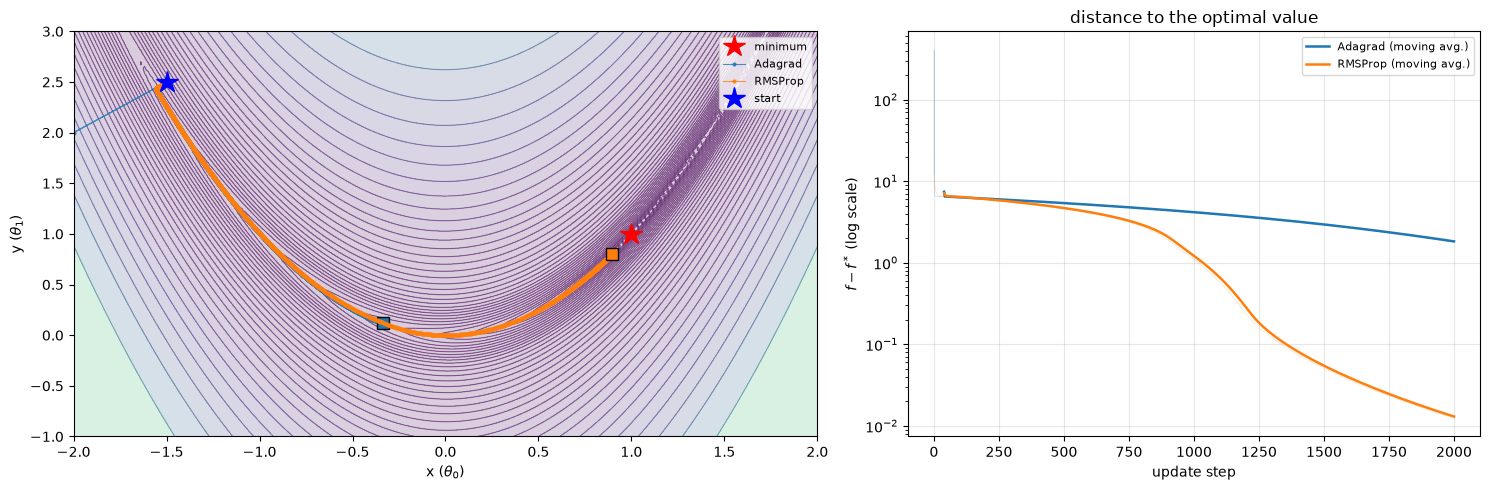

In [28]:
adagrad_lr = 0.5
rmsprop_lr = 0.003
gamma = 0.9
epochs = 2000

problem = get_problem('rosenbrock')
start = (-1.5, 2.5)
st_ada, st_rms = new_states('G'), new_states('v')
res = {
  'Adagrad': run_optimizer(rosenbrock, adagrad_update, start, {'lr': adagrad_lr, 'eps': 1e-10}, st_ada, epochs=epochs),
  'RMSProp': run_optimizer(rosenbrock, RMSProp_update, start, {'lr': rmsprop_lr, 'gamma': gamma, 'eps': 1e-8}, st_rms, epochs=epochs),
}
print('Adagrad effective lr per parameter at the end:', [f'{adagrad_lr / (g.sqrt().item() + 1e-10):.2e}' for g in st_ada['G']])
print('RMSProp effective lr per parameter at the end:', [f'{rmsprop_lr / (v.sqrt().item() + 1e-8):.2e}' for v in st_rms['v']])
plot_trajectories(problem, res)

In [29]:
#@title Extra runs for Section 4 (Adagrad's effective learning rate during the run above)
params_ = [torch.tensor(-1.5, requires_grad=True), torch.tensor(2.5, requires_grad=True)]
st_ = new_states('G')
for t_ in range(1, epochs + 1):
  g_ = compute_grads(rosenbrock(*params_), params_)
  with torch.no_grad():
    adagrad_update(params_, g_, st_, {'lr': adagrad_lr, 'eps': 1e-10})
  if t_ in (1, 10, 100, 1000, 2000):
    print(f'step {t_:4d}: |grad| = {torch.stack(g_).norm().item():7.2f},  '
          f'effective lr = {[f"{adagrad_lr / G.sqrt().item():.2e}" for G in st_["G"]]}')
for name, (tr_, ls_) in res.items():
  print(f'{name}: final loss = {ls_[-1]:.2e} at ({tr_[-1, 0]:.2f}, {tr_[-1, 1]:.2f}), '
        f'mean step length over the last 100 steps = {np.linalg.norm(np.diff(tr_[-101:], axis=0), axis=1).mean():.1e}')

step    1: |grad| =  153.38,  effective lr = ['3.45e-03', '1.00e-02']
step   10: |grad| =    1.89,  effective lr = ['3.09e-04', '1.23e-03']
step  100: |grad| =    1.91,  effective lr = ['3.09e-04', '1.23e-03']
step 1000: |grad| =    2.21,  effective lr = ['3.09e-04', '1.23e-03']


step 2000: |grad| =    2.43,  effective lr = ['3.08e-04', '1.22e-03']
Adagrad: final loss = 1.79e+00 at (-0.34, 0.12), mean step length over the last 100 steps = 9.3e-04
RMSProp: final loss = 1.25e-02 at (0.90, 0.80), mean step length over the last 100 steps = 4.2e-03


> Why does Adagrad slow down more and more, even in regions where the gradient is small? Why doesn't RMSProp?

Adagrad's $\mathbf G$ is a sum of squared gradients. It can only grow, so the effective learning rate $\eta/\sqrt{\mathbf G}$ can only shrink, and every gradient the method has ever seen keeps counting. On Rosenbrock the start point lies on the steep wall, and the first gradient has norm 153. After 10 steps $\mathbf G$ was already so large that the effective learning rates froze at $3.1\cdot10^{-4}$ for $x$ and $1.2\cdot10^{-3}$ for $y$. They still had the same values at step 2000. The later gradients in the valley have norm about 2, much too small to change $\mathbf G$. So Adagrad moves slowly in the flat valley, exactly where it should speed up. Its mean step over the last 100 steps was $9\cdot10^{-4}$, and it stopped at $f = 1.79$ at $(-0.34, 0.12)$, still far from $(1, 1)$.

RMSProp uses an exponential average, $\mathbf v \leftarrow \gamma\mathbf v + (1-\gamma)(\nabla f)^2$. With $\gamma = 0.9$ the weight of a gradient halves in about 7 steps, so the large gradients from the wall are forgotten and $\mathbf v$ follows the size of the current gradients. In the valley its effective learning rates went back up to $2.0\cdot10^{-3}$ and $3.6\cdot10^{-3}$, its steps were 4.5 times longer than Adagrad's, and it reached $f = 1.25\cdot10^{-2}$ at $(0.90, 0.80)$.

## 5. Adam

Adam (*Adaptive Moment Estimation*) keeps two exponentially weighted running averages for every parameter:

* the **first moment** $\mathbf m$, a running average of the gradient itself. Like the velocity in momentum, it smooths out gradient components that keep changing sign and builds up components that point the same way step after step. Unlike the momentum velocity, which is a decaying *sum* of past gradients, $\mathbf m$ is a weighted *average* (the new gradient is weighted by $1-\beta_1$), so its size stays on the scale of the gradient;
* the **second moment** $\mathbf v$, a running average of the *squared* gradient. As in RMSProp, it measures how large the gradients of each parameter typically are.

The update moves along the smoothed gradient $\mathbf m$ and divides it, element-wise, by $\sqrt{\mathbf v}$, so every parameter gets its own step size. This is why Adam is often described informally as "momentum + RMSProp": the first moment plays the role of momentum and the second moment plays the role of RMSProp's normalisation. The full update is:
\begin{align}
\mathbf m &\leftarrow \beta_1\mathbf m + (1-\beta_1)\nabla f, &\qquad \mathbf v &\leftarrow \beta_2\mathbf v + (1-\beta_2)(\nabla f)^2\\
\hat{\mathbf m} &= \frac{\mathbf m}{1-\beta_1^t}, &\qquad \hat{\mathbf v} &= \frac{\mathbf v}{1-\beta_2^t}\\
\mathbf w &\leftarrow \mathbf w - \eta\,\frac{\hat{\mathbf m}}{\sqrt{\hat{\mathbf v}}+\epsilon}
\end{align}
where $t$ is the number of steps taken so far (starting at $t=1$ for the first update). Because $\mathbf m$ and $\mathbf v$ start at zero, they are biased towards zero during the first steps; the division by $1-\beta^t$ is the **bias correction**.

With `hyper_params['bias_correction'] = False` the update uses $\mathbf m$ and $\mathbf v$ directly; Section 5.1 compares the two.

In [30]:
def adam_update(params, grads, states, hyper_params):
  # hyper-param typical values: lr=0.01, beta1=0.9, beta2=0.999, eps=1e-8, bias_correction=True
  lr, b1, b2, eps = hyper_params['lr'], hyper_params['beta1'], hyper_params['beta2'], hyper_params['eps']
  bias_correction = hyper_params.get('bias_correction', True)
  states['t'] += 1
  t = states['t']
  for i, (param, grad) in enumerate(zip(params, grads)):
    states['m'][i] = b1 * states['m'][i] + (1 - b1) * grad
    states['v'][i] = b2 * states['v'][i] + (1 - b2) * grad ** 2
    if bias_correction:
      m_hat = states['m'][i] / (1 - b1 ** t)
      v_hat = states['v'][i] / (1 - b2 ** t)
    else:
      m_hat, v_hat = states['m'][i], states['v'][i]
    param -= lr * m_hat / (v_hat.sqrt() + eps)


In [31]:
check_update(adam_update, torch.optim.Adam, {'lr': 0.05, 'betas': (0.9, 0.999), 'eps': 1e-8},
             {'lr': 0.05, 'beta1': 0.9, 'beta2': 0.999, 'eps': 1e-8}, new_states('m', 'v'))

[PASS] adam_update: after 30 steps mine = [-1.0147266  1.0705391], torch = [-1.0147266  1.0705391]


### 5.1 What does bias correction do?
Adam with and without bias correction, and the lengths of their first steps.

Adam                       first 5 step lengths: [0.0707 0.0559 0.0189 0.0095 0.0227]
Adam, no bias correction   first 5 step lengths: [0.2236 0.0952 0.1339 0.0144 0.104 ]


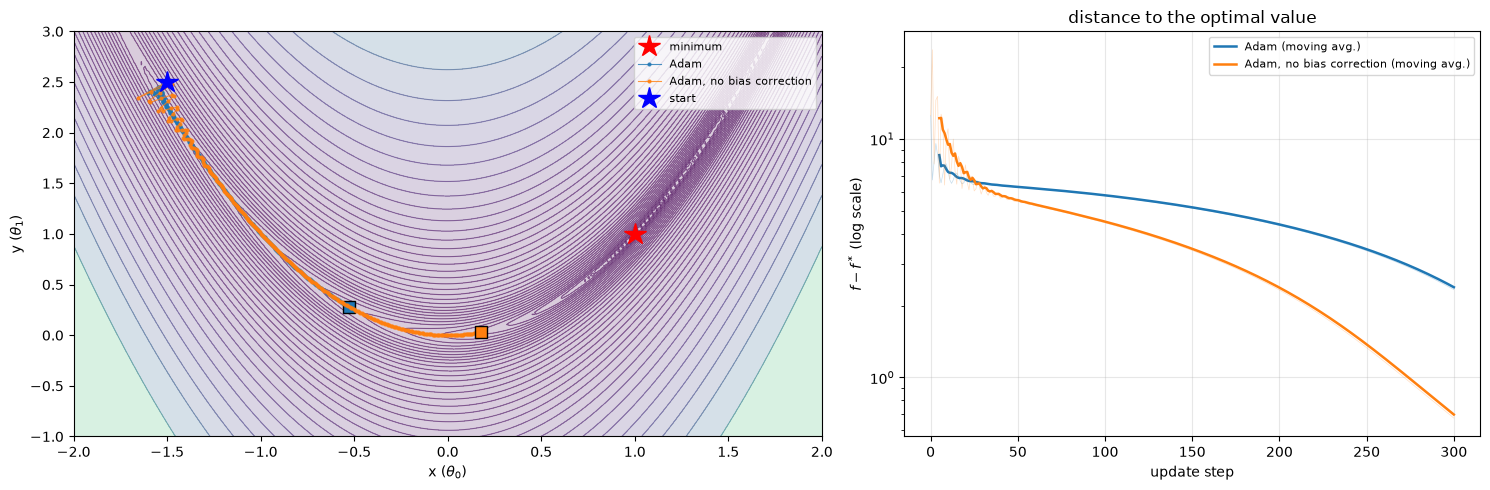

In [32]:
learning_rate = 0.05
beta1 = 0.9
beta2 = 0.999
epochs = 300

problem = get_problem('rosenbrock')
start = (-1.5, 2.5)
hp = {'lr': learning_rate, 'beta1': beta1, 'beta2': beta2, 'eps': 1e-8}
res = {
  'Adam': run_optimizer(rosenbrock, adam_update, start, {**hp, 'bias_correction': True}, new_states('m', 'v'), epochs=epochs),
  'Adam, no bias correction': run_optimizer(rosenbrock, adam_update, start, {**hp, 'bias_correction': False}, new_states('m', 'v'), epochs=epochs),
}
for name, (traj, _) in res.items():
  steps = np.linalg.norm(np.diff(traj[:6], axis=0), axis=1)
  print(f'{name:26s} first 5 step lengths:', np.round(steps, 4))
plot_trajectories(problem, res)

In [33]:
#@title Extra runs for Section 5.1
for name, (tr_, ls_) in res.items():
  print(f'{name:26s} loss after 10 / 100 / 300 steps: {ls_[10]:.2f} / {ls_[100]:.2f} / {ls_[300]:.2f}')
t_ = np.array([1, 10, 100, 1000, 3000])
print('t =', t_, ' -> without bias correction the step is larger by (1 - b1^t) / sqrt(1 - b2^t) =',
      np.round((1 - beta1 ** t_) / np.sqrt(1 - beta2 ** t_), 2))

Adam                       loss after 10 / 100 / 300 steps: 7.34 / 5.78 / 2.33
Adam, no bias correction   loss after 10 / 100 / 300 steps: 11.04 / 4.45 / 0.67
t = [   1   10  100 1000 3000]  -> without bias correction the step is larger by (1 - b1^t) / sqrt(1 - b2^t) = [3.16 6.53 3.24 1.26 1.03]


> What does bias correction fix, how long does it matter for given $\beta_1$ and $\beta_2$, and what happens to the first steps without it?

$\mathbf m$ and $\mathbf v$ start at zero, so during the first steps they are still mostly made of that initial zero. For a constant gradient $g$, $\mathbf m_t = (1-\beta_1^t)\,g$ and $\mathbf v_t = (1-\beta_2^t)\,g^2$: both underestimate their targets by the factor $1 - \beta^t$. Bias correction divides this factor out, so $\hat{\mathbf m}$ and $\hat{\mathbf v}$ are unbiased from the first step.

The factor is far from 1 only while $\beta^t$ is not small, which lasts a few multiples of $1/(1-\beta)$ steps. That is about 10 to 30 steps for $\beta_1 = 0.9$ and about 1000 to 3000 steps for $\beta_2 = 0.999$. At $t = 100$, $\mathbf v$ is still only 9.5% of its target. The larger $\beta$ is, the longer the correction matters.

Without correction $\mathbf v$ is underestimated much more than $\mathbf m$, so the step $\mathbf m/\sqrt{\mathbf v}$ is too large by $(1-\beta_1^t)/\sqrt{1-\beta_2^t}$. For the default betas this is 3.16 at $t = 1$, 6.5 at $t = 10$, 3.2 at $t = 100$ and 1.26 at $t = 1000$. My runs match this. The first step was 0.224 long without correction and 0.0707 with it ($0.0707 = \eta\sqrt2$, a step of exactly $\eta$ in each coordinate), and the next four steps were 1.5 to 7 times longer. On Rosenbrock this happened to help (loss 0.67 after 300 steps instead of 2.33), because $\eta = 0.05$ is small for this problem and the uncorrected version behaves like Adam with a learning rate several times larger.

In a real network the start of training is when the weights are random and the gradients are large and unreliable. Without correction Adam takes steps up to 6 times larger than the $\eta$ we chose, exactly then and for thousands of steps. That can blow up the loss or the activations, or push the weights into a bad region before training settles, and the effective learning rate depends on $t$ in a way we never chose.

### 5.2 Escaping a saddle point
GD, momentum, Adam and Newton start almost exactly on the saddle point's "ridge" (`start_y` very close to 0). Then I add gradient noise (`noise_std > 0`), which imitates the noise of stochastic gradients.

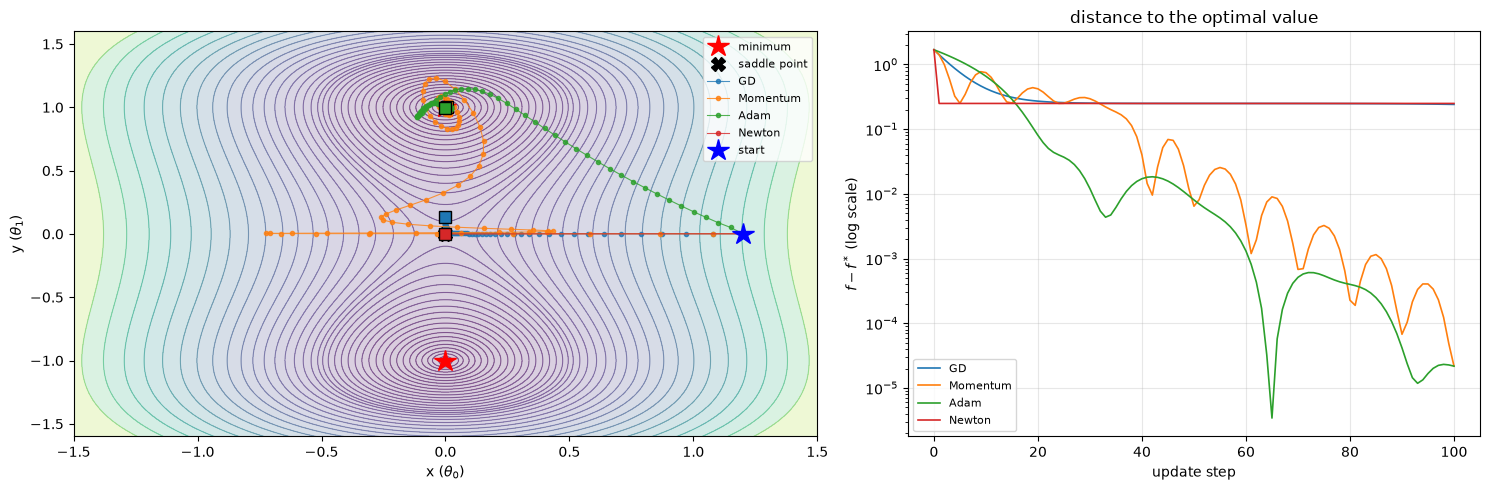

In [34]:
start_y = 0.001
noise_std = 0.0
epochs = 100

torch.manual_seed(1)
problem = get_problem('saddle')
start = (1.2, start_y)
res = {
  'GD': run_optimizer(saddle, GD_update, start, {'lr': 0.05}, epochs=epochs, noise_std=noise_std),
  'Momentum': run_optimizer(saddle, momentum_update, start, {'lr': 0.05, 'beta': 0.9}, new_states('delta'), epochs=epochs, noise_std=noise_std),
  'Adam': run_optimizer(saddle, adam_update, start, {'lr': 0.05, 'beta1': 0.9, 'beta2': 0.999, 'eps': 1e-8}, new_states('m', 'v'), epochs=epochs, noise_std=noise_std),
  'Newton': newton_method(saddle, start, lr=1., epochs=epochs, noise_std=noise_std),
}
plot_trajectories(problem, res)

In [35]:
#@title Extra runs for Section 5.2
import contextlib, io

def _leave(traj, thr=0.5):
  hit = np.where(np.abs(traj[:, 1]) > thr)[0]
  return int(hit[0]) if len(hit) else None

def _saddle_runs(start_y, noise, epochs, seed):
  torch.manual_seed(seed)
  st = (1.2, start_y)
  return {
    'GD': run_optimizer(saddle, GD_update, st, {'lr': 0.05}, epochs=epochs, noise_std=noise),
    'Momentum': run_optimizer(saddle, momentum_update, st, {'lr': 0.05, 'beta': 0.9}, new_states('delta'), epochs=epochs, noise_std=noise),
    'Adam': run_optimizer(saddle, adam_update, st, {'lr': 0.05, 'beta1': 0.9, 'beta2': 0.999, 'eps': 1e-8}, new_states('m', 'v'), epochs=epochs, noise_std=noise),
    'Newton': newton_method(saddle, st, lr=1., epochs=epochs, noise_std=noise),
  }

print('(a) start_y = 0.001, no noise, 100 steps: first step with |y| > 0.5')
for name, (tr_, _) in _saddle_runs(0.001, 0., 100, 1).items():
  print(f'  {name:8s} leaves at step {_leave(tr_)}, ends at ({tr_[-1, 0]:+.3f}, {tr_[-1, 1]:+.3f})')
print('    start_y = 0, no noise, end points:', {k: tuple(np.round(v[0][-1], 3).tolist()) for k, v in _saddle_runs(0., 0., 200, 0).items()})
print('(b) start_y = 0, noise_std = 0.1, 200 steps')
for seed in range(6):
  out_ = _saddle_runs(0., 0.1, 200, seed)
  row = ' | '.join(f'{k} leaves at {_leave(v[0])}, ends ({v[0][-1, 0]:+.2f}, {v[0][-1, 1]:+.2f})' for k, v in out_.items() if k != 'Newton')
  tn_ = out_['Newton'][0]
  print(f'  seed {seed}: {row} | Newton: max |y| = {np.abs(tn_[:, 1]).max():.2f}, ends ({tn_[-1, 0]:+.2f}, {tn_[-1, 1]:+.2f})')
print('(c) Newton alone, start_y = 0, 200 steps, 100 seeds each')
for noise in [0.1, 0.2]:
  escaped = []
  for seed in range(100):
    torch.manual_seed(seed)
    with contextlib.redirect_stdout(io.StringIO()):
      tn_, _ = newton_method(saddle, (1.2, 0.), lr=1., epochs=200, noise_std=noise)
    if np.abs(tn_[:, 1]).max() > 1 / math.sqrt(3):
      escaped.append((seed, tn_))
  print(f'  noise_std = {noise}: |y| passed 1/sqrt(3) in {len(escaped)} of 100 seeds')
  if noise == 0.1 and escaped:
    seed, tn_ = escaped[0]
    k_ = int(np.argmax(np.abs(tn_[:, 1]) > 1 / math.sqrt(3)))
    print(f'    seed {seed}: y around the escape = {np.round(tn_[k_ - 4:k_ + 4, 1], 3)}, ends at ({tn_[-1, 0]:+.2f}, {tn_[-1, 1]:+.2f})')

(a) start_y = 0.001, no noise, 100 steps: first step with |y| > 0.5
  GD       leaves at step None, ends at (+0.000, +0.130)
  Momentum leaves at step 37, ends at (+0.004, +1.001)
  Adam     leaves at step 11, ends at (-0.004, +0.997)
  Newton   leaves at step None, ends at (+0.000, +0.000)


    start_y = 0, no noise, end points: {'GD': (0.0, 0.0), 'Momentum': (0.0, 0.0), 'Adam': (-0.0, 0.0), 'Newton': (0.0, 0.0)}
(b) start_y = 0, noise_std = 0.1, 200 steps
  seed 0: GD leaves at 93, ends (-0.01, -1.00) | Momentum leaves at 24, ends (+0.05, -0.99) | Adam leaves at 17, ends (+0.01, -1.00) | Newton: max |y| = 0.25, ends (-0.00, -0.07)


  seed 1: GD leaves at 78, ends (-0.00, +0.99) | Momentum leaves at 17, ends (-0.02, -1.03) | Adam leaves at 31, ends (+0.03, -1.01) | Newton: max |y| = 0.34, ends (-0.02, +0.05)
  seed 2: GD leaves at 72, ends (-0.00, +1.02) | Momentum leaves at 20, ends (+0.04, -0.94) | Adam leaves at 11, ends (-0.01, +1.01) | Newton: max |y| = 0.41, ends (-0.00, +0.11)


  seed 3: GD leaves at 86, ends (+0.01, -1.01) | Momentum leaves at 20, ends (-0.01, +0.98) | Adam leaves at 11, ends (+0.02, -1.02) | Newton: max |y| = 0.31, ends (+0.01, -0.06)
  seed 4: GD leaves at 62, ends (+0.01, -1.00) | Momentum leaves at 26, ends (+0.01, -1.00) | Adam leaves at 13, ends (-0.00, +1.00) | Newton: max |y| = 0.27, ends (-0.03, -0.03)


  seed 5: GD leaves at 139, ends (-0.01, -0.99) | Momentum leaves at 16, ends (-0.04, +1.02) | Adam leaves at 14, ends (+0.00, -0.96) | Newton: max |y| = 0.34, ends (-0.07, -0.10)
(c) Newton alone, start_y = 0, 200 steps, 100 seeds each


  noise_std = 0.1: |y| passed 1/sqrt(3) in 2 of 100 seeds
    seed 8: y around the escape = [ 0.074 -0.007 -0.063  0.429 -0.668 -1.539 -1.191 -1.016], ends at (+0.06, -1.03)


  noise_std = 0.2: |y| passed 1/sqrt(3) in 100 of 100 seeds


> (a) How quickly do GD, momentum and Adam leave the saddle when they start very close to it, and why?
> (b) With `start_y = 0`, `noise_std = 0.1` and 200 steps over several seeds, how does gradient noise change the trajectories?
> (c) Does Newton stay near the saddle under the same noise?

**(a)** From $y_0 = 0.001$ without noise, the first step with $|y| > 0.5$ was step 11 for Adam and step 37 for momentum, and GD did not leave within 100 steps. Near the saddle $\partial f/\partial y \approx -y$, so GD multiplies $y$ by $1 + \eta = 1.05$ per step and only reached $0.001\cdot1.05^{100} = 0.13$. Momentum adds up these small gradients, which all point the same way, so its velocity in $y$ grows faster (up to $1/(1-\beta) = 10$ times a GD step). Adam divides by $\sqrt{\hat v}$, the size of the recent $y$-gradients. The $y$-gradient is tiny, but so is $\sqrt{\hat v}$, so Adam's step in $y$ is about $\eta$ however flat the saddle is. Newton converged to the saddle, as in Section 2.

**(b)** With `start_y = 0` and no noise, all four methods stay exactly at $(0, 0)$, because the $y$-gradient is exactly zero on the line $y = 0$. With `noise_std = 0.1`, GD, momentum and Adam left the saddle in all six seeds I ran (0 to 5): GD at steps 62 to 139, momentum at 16 to 26, Adam at 11 to 31. Every run ended at one of the two minima, and which one changed with the seed and the method, since the sign of the early random kicks decides the side. The noise moves the point off the line $y = 0$, and from there the negative curvature makes the offset grow, as in (a). So stochastic gradient noise turns an exact saddle into an unstable one: it can slow an optimizer down, but the optimizer is very unlikely to stay there.

**(c)** Newton stayed near the saddle in all six seeds: the largest $|y|$ in 200 steps was 0.25 to 0.41, and it ended within 0.11 of $(0, 0)$. Leaving is possible but rare. In a separate run with 100 seeds, $|y|$ passed $1/\sqrt3$ in 2 of them, and with `noise_std = 0.2` in all 100.

With noise $n$ in the $y$-gradient, Newton's update is $y_{new} = (2y^3 - n)/(3y^2 - 1)$, which is about $n$ when $y$ is small. Every step jumps back to the saddle, and the only offset left is the latest noise divided by $|H_{yy}|$; unlike GD, Newton does not accumulate the offset. While $|y|$ is small, $H_{yy} \approx -1$ and $y$ stays as small as the noise. If the noise happens to put $y$ where $H_{yy} = 3y^2 - 1$ is close to zero ($|y|$ near $1/\sqrt3 = 0.577$), dividing by the tiny curvature turns a small noise into a huge step. In seed 8 the sequence was $y = -0.063,\ 0.429,\ -0.668,\ -1.539$: at $y = 0.429$, $|H_{yy}| = 0.45$, and the step overshot past $-1/\sqrt3$. Once $|y| > 1/\sqrt3$ the curvature is positive, Newton is attracted to the minimum on that side, and it ended at $(0.06, -1.03)$. So the sign of $H_{yy}$ decides whether Newton is pulled toward the saddle or toward a minimum, and its magnitude decides how much the noise is amplified.

### 5.3 Per-parameter scaling vs. rotation
RMSProp and Adam rescale each **coordinate** separately. Newton rescales along the **eigenvectors** of the Hessian. Below they run, together with GD, on the ill-conditioned quadratic while the rotation `angle` goes from $0°$ to $45°$. The start point is rotated together with the problem, so for GD and Newton the problem is *exactly the same* at every angle (their trajectories simply rotate).

GD (lr = 1/kappa)                  steps to reach f < 1e-3: 109
RMSProp (lr = 0.05, gamma = 0.99)  steps to reach f < 1e-3: 17
Adam (lr = 0.05)                   steps to reach f < 1e-3: 57
Newton                             steps to reach f < 1e-3: 1


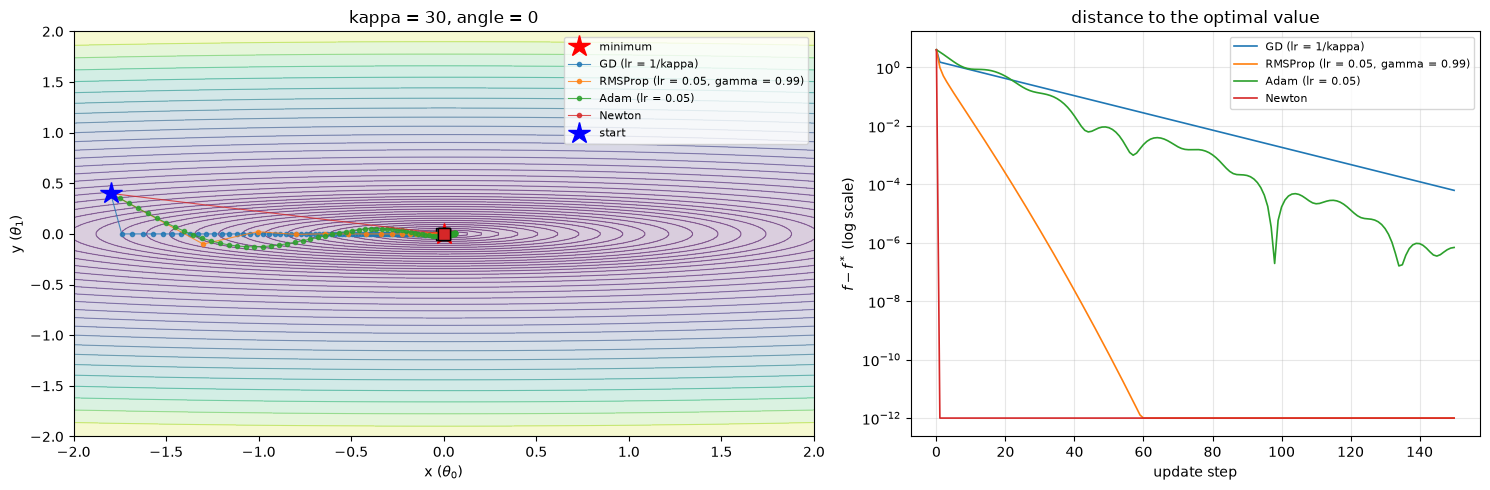

In [36]:
kappa = 30
angle = 0
epochs = 150

problem = get_problem('quadratic', kappa, angle)
a = math.radians(angle)
start = (-1.8 * math.cos(a) - 0.4 * math.sin(a), -1.8 * math.sin(a) + 0.4 * math.cos(a))
res = {
  'GD (lr = 1/kappa)': run_optimizer(problem[0], GD_update, start, {'lr': 1. / kappa}, epochs=epochs),
  'RMSProp (lr = 0.05, gamma = 0.99)': run_optimizer(problem[0], RMSProp_update, start, {'lr': 0.05, 'gamma': 0.99, 'eps': 1e-8}, new_states('v'), epochs=epochs),
  'Adam (lr = 0.05)': run_optimizer(problem[0], adam_update, start, {'lr': 0.05, 'beta1': 0.9, 'beta2': 0.999, 'eps': 1e-8}, new_states('m', 'v'), epochs=epochs),
  'Newton': newton_method(problem[0], start, lr=1., epochs=epochs),
}
for name, (traj, losses) in res.items():
  hit = np.where(losses < 1e-3)[0]
  print(f'{name:34s} steps to reach f < 1e-3: {hit[0] if len(hit) else "not reached"}')
plot_trajectories(problem, res, title=f'kappa = {kappa}, angle = {angle}')

In [37]:
#@title Extra runs for Section 5.3 (steps to reach f < 1e-3; "-" = not within 150 steps)
def _rot_start(angle):
  a = math.radians(angle)
  return (-1.8 * math.cos(a) - 0.4 * math.sin(a), -1.8 * math.sin(a) + 0.4 * math.cos(a))

def _hit(losses, tol=1e-3):
  h = np.where(np.asarray(losses) < tol)[0]
  return int(h[0]) if len(h) else '-'

print('angle | GD lr=1/kappa | GD lr=2/(1+kappa) | RMSProp lr=0.05 | Adam lr=0.05 | Newton')
for ang in [0, 10, 20, 30, 45]:
  f_, s_ = get_problem('quadratic', 30, ang)[0], _rot_start(ang)
  row = [run_optimizer(f_, GD_update, s_, {'lr': 1 / 30}, epochs=150)[1],
         run_optimizer(f_, GD_update, s_, {'lr': 2 / 31}, epochs=150)[1],
         run_optimizer(f_, RMSProp_update, s_, {'lr': 0.05, 'gamma': 0.99, 'eps': 1e-8}, new_states('v'), epochs=150)[1],
         run_optimizer(f_, adam_update, s_, {'lr': 0.05, 'beta1': 0.9, 'beta2': 0.999, 'eps': 1e-8}, new_states('m', 'v'), epochs=150)[1],
         newton_method(f_, s_, lr=1., epochs=150)[1]]
  print(f'{ang:5d} | ' + ' | '.join(f'{str(_hit(l)):>8}' for l in row))
print('learning-rate sensitivity, steps for lr = 0.02 / 0.05 / 0.1 / 0.2:')
for ang in [0, 45]:
  f_, s_ = get_problem('quadratic', 30, ang)[0], _rot_start(ang)
  for name, fn, keys, extra in [('RMSProp', RMSProp_update, ('v',), {'gamma': 0.99}),
                                ('Adam', adam_update, ('m', 'v'), {'beta1': 0.9, 'beta2': 0.999})]:
    hits = [_hit(run_optimizer(f_, fn, s_, {'lr': lr_, 'eps': 1e-8, **extra}, new_states(*keys), epochs=150)[1])
            for lr_ in [0.02, 0.05, 0.1, 0.2]]
    print(f'  angle {ang:2d}, {name:7s}: {hits}')

angle | GD lr=1/kappa | GD lr=2/(1+kappa) | RMSProp lr=0.05 | Adam lr=0.05 | Newton
    0 |      109 |       63 |       17 |       57 |        1


   10 |      109 |       63 |       31 |       69 |        1
   20 |      109 |       63 |       48 |       95 |        1


   30 |      109 |       63 |       62 |      114 |        1
   45 |      109 |       63 |       72 |      122 |        1
learning-rate sensitivity, steps for lr = 0.02 / 0.05 / 0.1 / 0.2:


  angle  0, RMSProp: [73, 17, 6, 5]
  angle  0, Adam   : ['-', 57, 48, 47]


  angle 45, RMSProp: [139, 72, 75, 80]
  angle 45, Adam   : ['-', 122, 63, 34]


> Which methods are affected by rotating the problem? Why can per-coordinate scaling (RMSProp, Adam) help when the high- and low-curvature directions line up with the axes, and why is that no guarantee?

GD and Newton are not affected by the rotation. GD needed 109 steps with $\eta = 1/\kappa$ (63 with $\eta = 2/(1+\kappa)$) at every angle, and Newton always needed 1. GD's step $-\eta\nabla f$ rotates with the problem, and so does Newton's $\mathbf H^{-1}\nabla f$, so their trajectories just rotate. RMSProp and Adam are affected: RMSProp needed 17, 31, 48, 62 and 72 steps at 0°, 10°, 20°, 30° and 45°, and Adam needed 57, 69, 95, 114 and 122.

At 0° the eigenvectors of $\mathbf A$ are the coordinate axes, so $x$ only feels the flat curvature and $y$ only the steep one. The gradient in $y$ is large and the gradient in $x$ is small, and dividing each coordinate by its own $\sqrt v$ gives the flat direction a large step and the steep direction a small one. This acts like a diagonal approximation of Newton's $\mathbf H^{-1}$, and at 0° the Hessian really is diagonal. At 45° each coordinate is a mix of the steep and the flat direction, both coordinates see gradients of similar size, and the per-coordinate scaling can no longer separate the two directions. The method then behaves like GD with a normalized step.

This does not guarantee better performance, because the advantage depends on the alignment and on the learning rate. At 45°, Adam with $\eta = 0.05$ (122 steps) was slower than GD with a well-chosen $\eta$ (63 steps). The comparison also changes with $\eta$: at 45° Adam needed 122 steps with $\eta = 0.05$ and 34 with $\eta = 0.2$, and at 0° RMSProp needed 73 steps with $\eta = 0.02$ and 5 with $\eta = 0.2$. With one fixed learning rate per method, the comparison partly measures which method that learning rate suits. A fair comparison tunes each method's learning rate separately.

For neural networks this suggests that Adam's per-parameter learning rates help most when gradient scales differ between individual parameters. Examples are different layers, biases and weights, or embeddings of rare and frequent tokens, where some parameters get large or frequent gradients and others small or rare ones. They help less when the badly conditioned directions are combinations of many parameters, since a per-coordinate scale cannot fix those.

## 6. Stochastic and mini-batch gradient descent

So far every step used the *exact* gradient. For a loss defined on data, $\mathcal L(\boldsymbol\theta) = \frac1N\sum_i \ell_i(\boldsymbol\theta)$, computing it needs a pass over all $N$ samples. Instead we can estimate it on a small random **mini-batch** $\mathcal B$ of size $b$:
$$\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\,\nabla_{\boldsymbol\theta}\,\frac1b\sum_{i\in\mathcal B}\ell_i(\boldsymbol\theta)$$
* $b = N$: **batch** gradient descent (one update per epoch)
* $b = 1$: **stochastic** gradient descent (SGD, $N$ updates per epoch)
* $1 < b < N$: **mini-batch** gradient descent

In every epoch we go through all samples once, in an order that is decided at the start of the epoch.

`run_minibatch` picks the order of the samples at the start of each epoch according to `order`:
* `'shuffle'`: a new random permutation every epoch,
* `'fixed'`: the same random permutation every epoch,
* `'sorted'`: samples sorted by their target $y$.

Then, for each batch (the last one may be smaller), it computes the batch loss and its gradients and calls the update function inside `torch.no_grad()`.

In [38]:
def run_minibatch(update_func, start, hyper_params, states=None, batch_size=10, epochs=10,
                  order='shuffle', seed=0, lr_schedule=None):
  torch.manual_seed(seed)
  params = [torch.tensor(float(v), requires_grad=True) for v in start]
  states = {} if states is None else states
  hyper_params = dict(hyper_params)
  fixed_perm = torch.randperm(N)
  traj = [[p.item() for p in params]]
  losses = [regression_loss(*params).item()]      # full training loss, for monitoring only
  t = 0                                           # number of updates so far (used by lr_schedule, Section 6.4)
  for epoch in range(epochs):
    # 1. choose the order of the samples for this epoch
    if order == 'shuffle':
      perm = torch.randperm(N)
    elif order == 'fixed':
      perm = fixed_perm
    elif order == 'sorted':
      perm = torch.argsort(Y_data)
    else:
      raise ValueError(f'unknown order {order!r}')
    for s in range(0, N, batch_size):
      if lr_schedule is not None:
        hyper_params['lr'] = lr_schedule(t)
      # 2. take the batch starting at position s, compute its loss and gradients, and update the params
      idx = perm[s:s + batch_size]
      loss = regression_loss(*params, X_data[idx], Y_data[idx])
      grads = compute_grads(loss, params)
      with torch.no_grad():
        update_func(params, grads, states, hyper_params)
      t += 1
      traj.append([p.item() for p in params])
      losses.append(regression_loss(*params).item())
  return np.array(traj), np.array(losses)

### 6.1 Batch vs. mini-batch vs. stochastic
All three runs use the same learning rate and the same number of **epochs**.

**Note:** an *epoch* is one pass over all $N$ samples, while an *update* is one parameter step. The three runs therefore make very different numbers of updates per epoch: $1$ (batch), $N/b$ (mini-batch) and $N$ (stochastic).

Stochastic (b=1)       updates:  2000   final loss - f*: 3.78e-02
Mini-batch (b=10)      updates:   200   final loss - f*: 1.88e-05
Batch (b=100)          updates:    20   final loss - f*: 8.43e-03


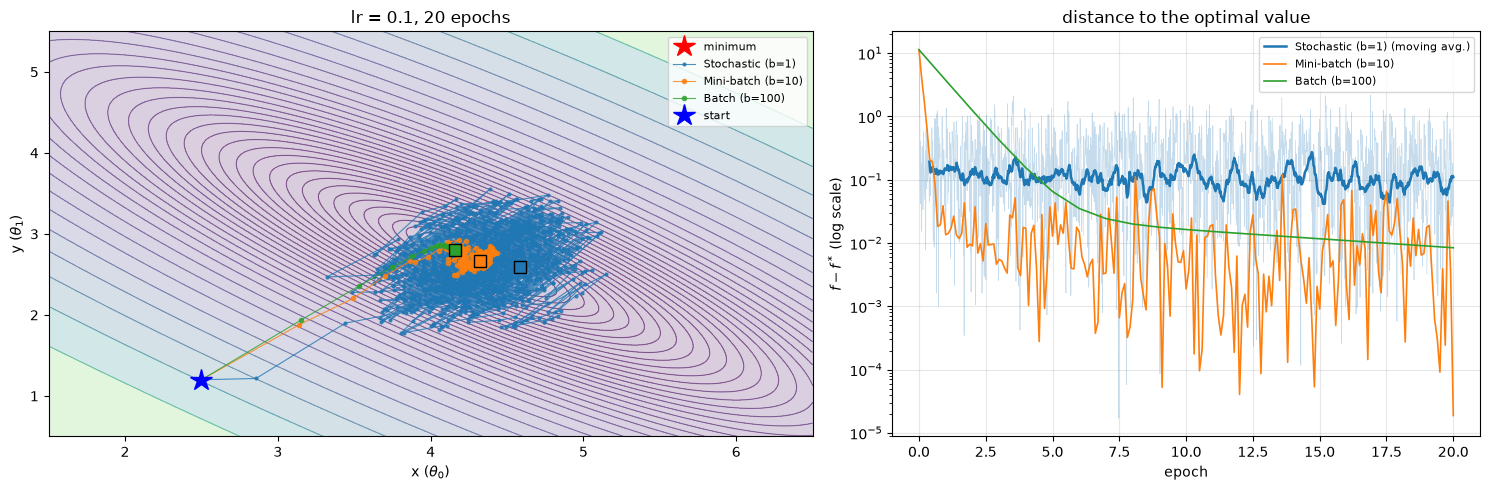

In [39]:
learning_rate = 0.1
epochs = 20
mini_batch_size = 10

problem = get_problem('regression')
start = (2.5, 1.2)
hp = {'lr': learning_rate}
res = {
  'Stochastic (b=1)': run_minibatch(GD_update, start, hp, batch_size=1, epochs=epochs),
  f'Mini-batch (b={mini_batch_size})': run_minibatch(GD_update, start, hp, batch_size=mini_batch_size, epochs=epochs),
  f'Batch (b={N})': run_minibatch(GD_update, start, hp, batch_size=N, epochs=epochs),
}
for name, (traj, losses) in res.items():
  print(f'{name:22s} updates: {len(traj) - 1:5d}   final loss - f*: {losses[-1] - reg_f_star:.2e}')
plot_trajectories(problem, res, title=f'lr = {learning_rate}, {epochs} epochs',
                  updates_per_epoch={name: (len(r[0]) - 1) / epochs for name, r in res.items()})

In [40]:
#@title Extra runs for Section 6.1
for name, (tr_, ls_) in res.items():
  gap_ = ls_ - reg_f_star
  upe_ = (len(tr_) - 1) // epochs
  k_ = int(np.argmax(gap_ < 1e-2)) if (gap_ < 1e-2).any() else None
  reach = f'{k_} updates = {k_ / upe_:.2f} epochs' if k_ is not None else 'never'
  print(f'{name:20s} first f - f* < 1e-2 after {reach:25s} mean f - f* in the last epoch = {gap_[-upe_:].mean():.1e},  '
        f'updates that increased the full loss: {np.mean(np.diff(ls_) > 0):.0%}')

Stochastic (b=1)     first f - f* < 1e-2 after 25 updates = 0.25 epochs  mean f - f* in the last epoch = 2.3e-01,  updates that increased the full loss: 48%
Mini-batch (b=10)    first f - f* < 1e-2 after 18 updates = 1.80 epochs  mean f - f* in the last epoch = 7.7e-03,  updates that increased the full loss: 46%
Batch (b=100)        first f - f* < 1e-2 after 18 updates = 18.00 epochs mean f - f* in the last epoch = 8.4e-03,  updates that increased the full loss: 0%


> (a) Why is SGD called *stochastic*?
> (b) Why does the SGD path sometimes move uphill on the contours of the full loss?
> (c) Which method reaches a low loss in the fewest epochs, and which in the fewest updates? Why does deep learning use mini-batches?

**(a)** Each update uses the gradient of one randomly chosen sample. That gradient is a random variable whose expected value is the full gradient, so every step, and the whole path, depends on the random order of the samples.

**(b)** An SGD step goes downhill for the loss of one sample, $\ell_i$, whose gradient can point a different way from the gradient of the full loss $\mathcal L$. Near the minimum the full gradient is small while the single-sample gradients are not (each sample has its own noise in $y$), so many steps go uphill on the contours of $\mathcal L$. In my run 48% of the SGD updates and 46% of the mini-batch updates increased the full loss; full-batch GD never did.

**(c)** In epochs SGD was fastest: it first reached $f - f^* < 10^{-2}$ after 0.25 epochs, against 1.8 for mini-batch and 18 for batch GD. In updates, mini-batch and batch GD tied at 18 and SGD needed 25. SGD then stopped improving: its mean gap over the last epoch was 0.23, against $7.7\cdot10^{-3}$ for mini-batch and $8.4\cdot10^{-3}$ for batch GD.

Mini-batches combine the good parts of both. They make many updates per epoch, as SGD does, but each update is about $b$ times less noisy (Section 6.2). On a GPU a batch of $b$ samples also takes about as long as one sample, because the samples are processed in parallel. Full-batch GD makes one update per pass over the whole dataset, which is far too slow for millions of samples, and the whole dataset does not fit in memory anyway.

### 6.2 The variance of the gradient estimate
The mini-batch gradient is an **unbiased** estimate of the full gradient, and its variance should shrink as $1/b$. Let's measure it.

`minibatch_grad_variance` draws `n_trials` mini-batches of size `b` at a fixed point $\boldsymbol\theta$ (indices sampled with replacement), computes each mini-batch gradient, and returns the total variance across trials, summed over the two parameters.

In [41]:
def minibatch_grad_variance(theta, b, n_trials=500):
  params = [torch.tensor(float(v), requires_grad=True) for v in theta]
  samples = []
  for _ in range(n_trials):
    idx = torch.randint(0, N, (b,))                     # with replacement
    loss = regression_loss(*params, X_data[idx], Y_data[idx])
    samples.append(torch.stack(compute_grads(loss, params)))
  samples = torch.stack(samples)                         # (n_trials, 2)
  return samples.var(dim=0).sum().item()                 # total variance = trace of the covariance


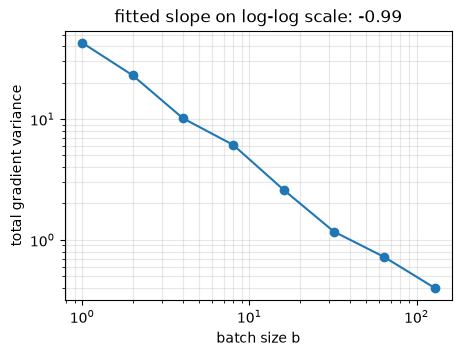

In [42]:
#@title Variance vs batch size
batch_sizes = [1, 2, 4, 8, 16, 32, 64, 128]
variances = [minibatch_grad_variance((2.5, 1.2), b) for b in batch_sizes]
slope = np.polyfit(np.log(batch_sizes), np.log(variances), 1)[0]
plt.figure(figsize=(5, 3.5))
plt.loglog(batch_sizes, variances, 'o-')
plt.xlabel('batch size b'); plt.ylabel('total gradient variance')
plt.title(f'fitted slope on log-log scale: {slope:.2f}'); plt.grid(alpha=0.3, which='both');

> How does the noise in the gradient estimate depend on the batch size, and why doesn't a larger batch always train faster for the same computation?

At $\boldsymbol\theta = (2.5, 1.2)$ the total variance fell from 42.8 at $b = 1$ to 0.40 at $b = 128$, and the fitted log-log slope is $-0.99$. So the variance is proportional to $1/b$, as for any mean of $b$ independent samples, and the standard deviation of the noise only falls as $1/\sqrt b$: halving the noise needs a 4 times larger batch.

A batch of size $b$ costs $b$ sample gradients, so one epoch gives $N/b$ updates. Going from $b = 1$ to $b = 4$ gives 4 times fewer updates in exchange for half the noise. Far from the minimum the true gradient is much larger than the noise, and many slightly noisy steps make more progress than a few accurate ones. In Section 6.1 SGD reached $f - f^* < 10^{-2}$ in 0.25 epochs, while full-batch GD needed 18 epochs. A larger batch pays off only near the minimum, where the gradient is small and the noise dominates: there SGD stayed at a gap of 0.23 while $b = 10$ reached $7.7\cdot10^{-3}$. Beyond some batch size the extra computation buys almost nothing.

### 6.3 Order of presentation
SGD ($b=1$) with the three orderings and a constant learning rate. The interesting part is the *last* epochs of each trajectory.

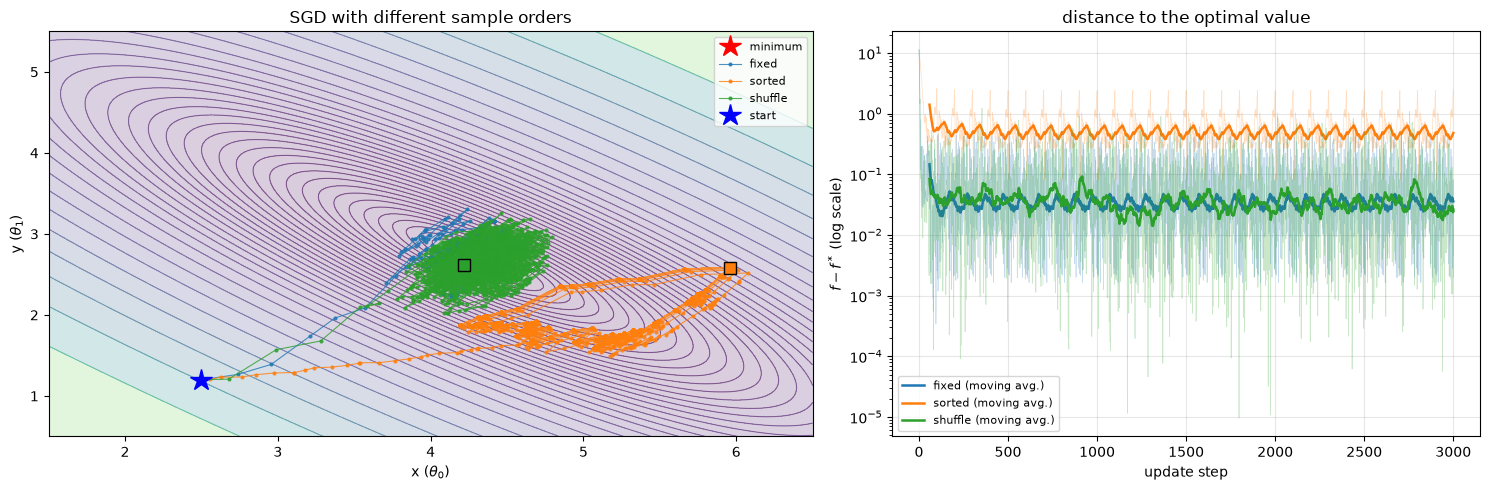

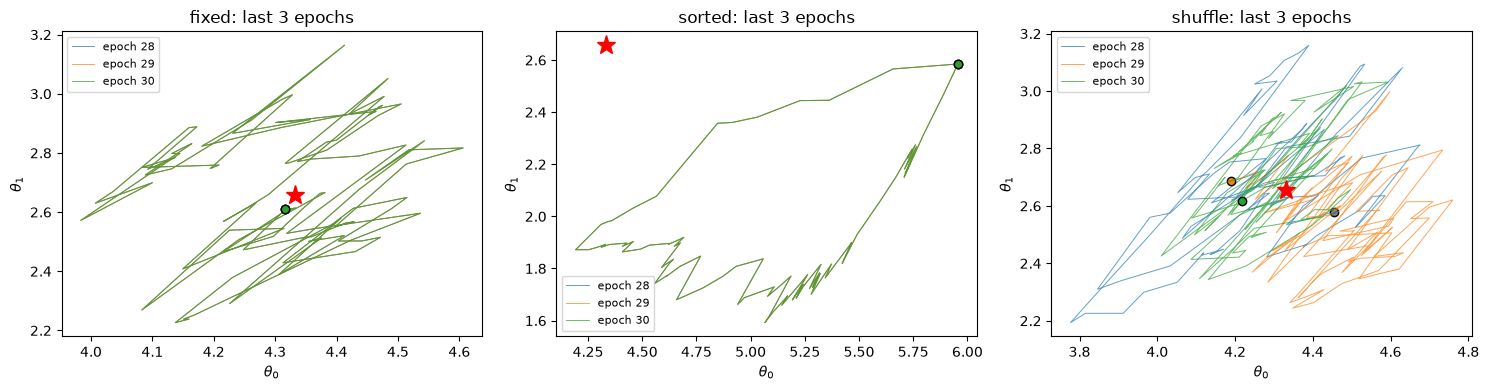

In [43]:
learning_rate = 0.05
epochs = 30

problem = get_problem('regression')
start = (2.5, 1.2)
res = {o: run_minibatch(GD_update, start, {'lr': learning_rate}, batch_size=1, epochs=epochs, order=o)
       for o in ['fixed', 'sorted', 'shuffle']}
plot_trajectories(problem, res, title='SGD with different sample orders')

# zoom in on the last 3 epochs (dots: parameters at the end of each epoch)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (o, (traj, _)) in zip(axes, res.items()):
  for e, c in zip([3, 2, 1], ['tab:blue', 'tab:orange', 'tab:green']):
    seg = traj[len(traj) - 1 - e * N: len(traj) - (e - 1) * N]
    ax.plot(seg[:, 0], seg[:, 1], '-', lw=0.7, color=c, alpha=0.7, label=f'epoch {epochs - e + 1}')
    ax.plot(*seg[-1], 'o', color=c, mec='k')
  ax.plot(*theta_star.numpy(), 'r*', ms=14); ax.legend(fontsize=8)
  ax.set_title(f'{o}: last 3 epochs'); ax.set_xlabel(r'$\theta_0$'); ax.set_ylabel(r'$\theta_1$')
plt.tight_layout()

In [44]:
#@title Extra runs for Section 6.3 (parameters at the end of the last 3 epochs)
for o, (tr_, ls_) in res.items():
  ends_ = tr_[N::N][-3:]
  print(f'{o:8s} end-of-epoch points: {np.round(ends_, 3).tolist()},  distance of the last one to the minimum: '
        f'{np.linalg.norm(ends_[-1] - theta_star.numpy()):.3f},  final f - f* = {ls_[-1] - reg_f_star:.1e}')
print('y of the last 10 samples in the sorted order:', np.round(Y_data[torch.argsort(Y_data)[-10:]].numpy(), 1),
      f' (mean y = {Y_data.mean().item():.2f})')

fixed    end-of-epoch points: [[4.317, 2.609], [4.317, 2.609], [4.317, 2.609]],  distance of the last one to the minimum: 0.050,  final f - f* = 4.7e-03
sorted   end-of-epoch points: [[5.956, 2.585], [5.956, 2.585], [5.956, 2.585]],  distance of the last one to the minimum: 1.626,  final f - f* = 2.4e+00
shuffle  end-of-epoch points: [[4.454, 2.579], [4.189, 2.686], [4.217, 2.617]],  distance of the last one to the minimum: 0.122,  final f - f* = 2.4e-02
y of the last 10 samples in the sorted order: [ 9.6  9.7  9.8  9.8  9.9  9.9 10.5 10.6 10.6 10.9]  (mean y = 6.93)


> (a) With the `fixed` order, why do the last epochs trace the same loop and the end-of-epoch points coincide?
> (b) Why is the `sorted` order so much worse?
> (c) What does this mean for data loaders?

**(a)** With the `fixed` order and a constant learning rate, every epoch applies the same 100 updates in the same order, so one epoch is a fixed deterministic map $\boldsymbol\theta_{e+1} = \Phi(\boldsymbol\theta_e)$. Each single update of linear regression is an affine map, and for a small $\eta$ their composition over one epoch shrinks distances (the samples cover both directions of $\boldsymbol\theta$). So $\Phi$ has a single fixed point, and the end-of-epoch points converge to it: in my run they were $(4.317, 2.609)$ in each of the last three epochs. Starting from the same point and making the same 100 steps traces the same loop every time. The fixed point is 0.05 away from $\boldsymbol\theta^*$, because the last samples in the order always pull in the same direction.

**(b)** In the `sorted` order every epoch ends with the samples that have the largest $y$: the last ten have $y$ between 9.6 and 10.9, while the mean is 6.93. With $b = 1$ and $\eta = 0.05$, the last few dozen steps of every epoch all push the line upward, so the model fits these samples and forgets the rest. Its end-of-epoch point was $(5.96, 2.59)$, 1.63 away from the minimum, with $f - f^* = 2.4$ at the end, against $4.7\cdot10^{-3}$ for `fixed` and $2.4\cdot10^{-2}$ for `shuffle`. Consecutive samples in this order are strongly correlated, so over a short window their gradients do not average out to the full gradient.

**(c)** A data loader should reshuffle the data at every epoch (`shuffle=True` in PyTorch's `DataLoader`), and data should never be fed sorted by label, target, time or source. With a fresh shuffle the errors of each epoch are random and average out over epochs, while a fixed or sorted order builds one systematic bias into every epoch.

### 6.4 Learning-rate decay
In Sections 6.1 and 6.3, SGD with a constant learning rate gets close to the minimum quickly but then keeps jumping around it and never settles. A common fix is to **decrease the learning rate during training** according to a *schedule* $\eta_t$, where $t = 0, 1, \dots, T-1$ counts the updates and $T$ is the total number of updates.

`get_lr(t, T, base_lr, kind)` returns $\eta_t$ for these schedules ($\eta_0$ is `base_lr`, and $\tau = T/20$):

| `kind` | $\eta_t$ |
|---|---|
| `'constant'` | $\eta_0$ |
| `'step'` | $\eta_0$, multiplied by $0.1$ when $t \ge T/2$ and again by $0.1$ when $t \ge 3T/4$ |
| `'inverse'` | $\eta_0\,\dfrac{\tau}{\tau + t}$ |
| `'cosine'` | $\tfrac12\,\eta_0\,\big(1 + \cos(\pi t / T)\big)$ |

`run_minibatch` already accepts an `lr_schedule` argument: a function of `t` that is called before every update to set the learning rate.

In [45]:
def get_lr(t, T, base_lr, kind):
  """Learning rate at update step t (t = 0, 1, ..., T - 1) of a run with T updates in total."""
  tau = T / 20
  if kind == 'constant':
    return base_lr
  if kind == 'step':
    lr = base_lr
    if t >= T / 2:
      lr *= 0.1
    if t >= 3 * T / 4:
      lr *= 0.1
    return lr
  if kind == 'inverse':
    return base_lr * tau / (tau + t)
  if kind == 'cosine':
    return 0.5 * base_lr * (1 + math.cos(math.pi * t / T))
  raise ValueError(f'unknown schedule {kind!r}')


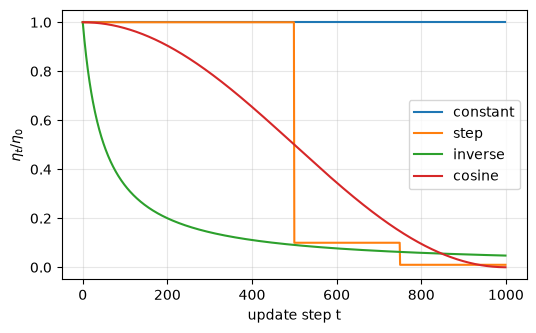

[PASS] schedule values


In [46]:
#@title Plot the schedules and check them
KINDS = ['constant', 'step', 'inverse', 'cosine']
T = 1000
expected = {('constant', 300): 1.0, ('step', 499): 1.0, ('step', 500): 0.1, ('step', 750): 0.01,
            ('inverse', 50): 0.5, ('inverse', 150): 0.25, ('cosine', 0): 1.0, ('cosine', 500): 0.5}
try:
  ok = all(abs(get_lr(t, T, 1., k) - v) < 1e-9 for (k, t), v in expected.items())
  plt.figure(figsize=(6, 3.5))
  for kind in KINDS:
    plt.plot([get_lr(t, T, 1., kind) for t in range(T)], label=kind)
  plt.xlabel('update step t'); plt.ylabel(r'$\eta_t / \eta_0$'); plt.legend(); plt.grid(alpha=0.3); plt.show()
except Exception as e:
  ok = False
  print('error:', repr(e))
print(('[PASS] ' if ok else '[FAIL] ') + 'schedule values')

SGD on the regression problem with each schedule, all from the same base learning rate. The bottom row zooms in on the last epoch. The extra runs after it repeat the comparison with `batch_size = 10`.

constant  last epoch: mean (loss - f*) = 2.3e-01,   mean distance to the minimum = 0.341
step      last epoch: mean (loss - f*) = 1.2e-04,   mean distance to the minimum = 0.013
inverse   last epoch: mean (loss - f*) = 2.4e-03,   mean distance to the minimum = 0.029
cosine    last epoch: mean (loss - f*) = 2.0e-04,   mean distance to the minimum = 0.010


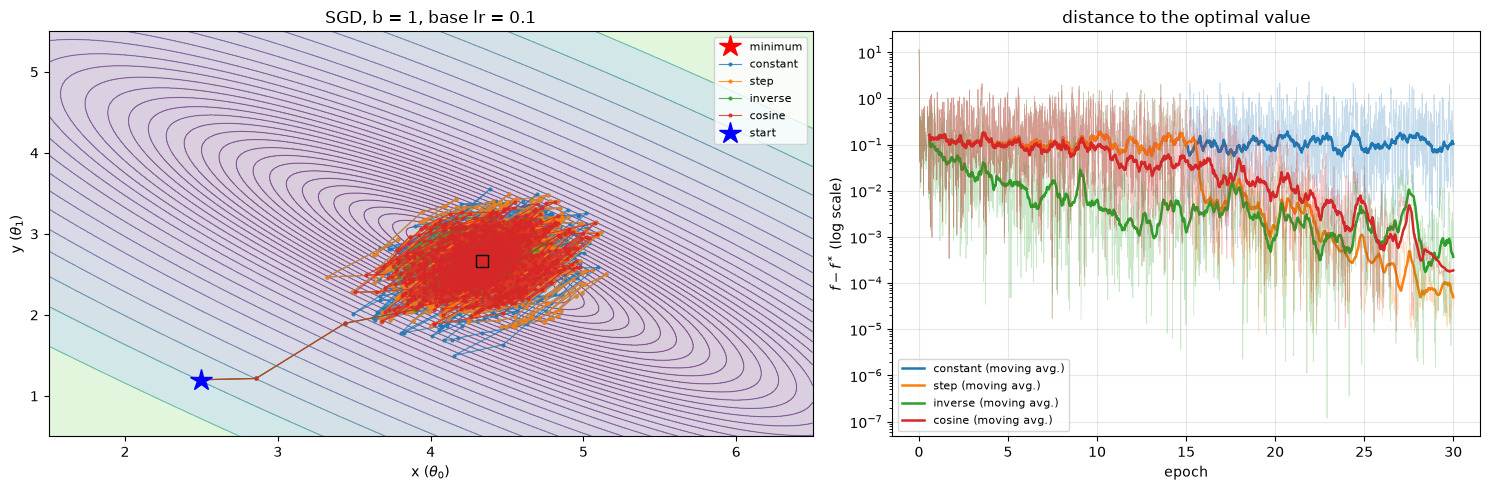

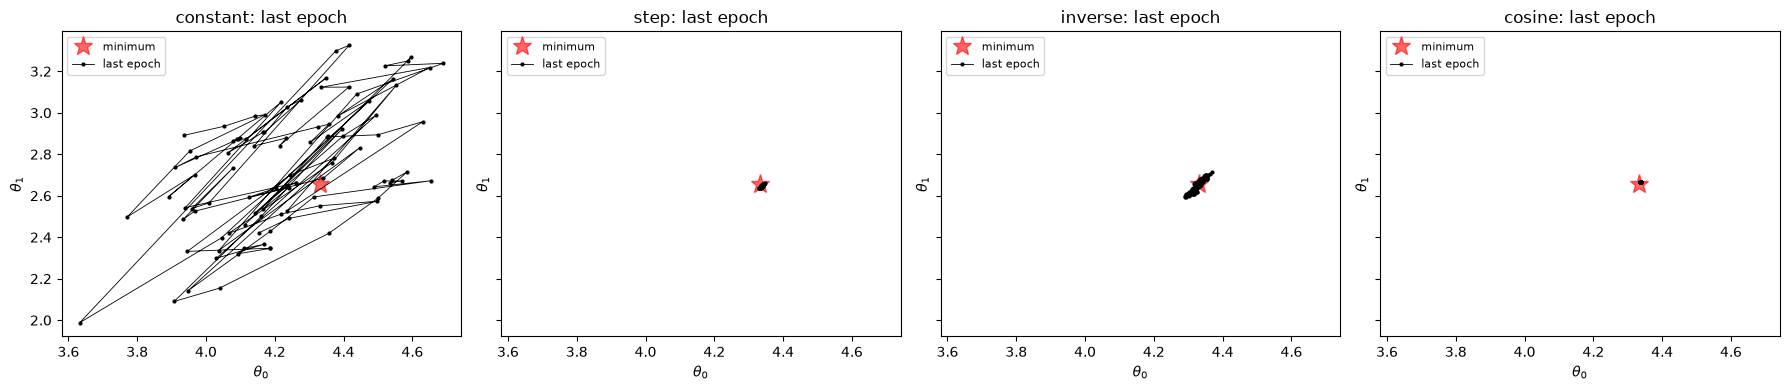

In [47]:
base_lr = 0.1
batch_size = 1
epochs = 30

problem = get_problem('regression')
start = (2.5, 1.2)
T = epochs * math.ceil(N / batch_size)          # total number of updates
res = {
  kind: run_minibatch(GD_update, start, {'lr': base_lr}, batch_size=batch_size, epochs=epochs,
                      lr_schedule=lambda t, kind=kind: get_lr(t, T, base_lr, kind))
  for kind in ['constant', 'step', 'inverse', 'cosine']
}
updates_last_epoch = math.ceil(N / batch_size)
for name, (traj, losses) in res.items():
  gap = np.mean(losses[-updates_last_epoch:] - reg_f_star)
  spread = np.linalg.norm(traj[-updates_last_epoch:] - theta_star.numpy(), axis=1).mean()
  print(f'{name:9s} last epoch: mean (loss - f*) = {gap:.1e},   mean distance to the minimum = {spread:.3f}')
plot_trajectories(problem, res, title=f'SGD, b = {batch_size}, base lr = {base_lr}',
                  updates_per_epoch={name: (len(r[0]) - 1) / epochs for name, r in res.items()})

# zoom in on the parameters visited during the last epoch (same axis limits in all panels)
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharex=True, sharey=True)
for ax, (name, (traj, _)) in zip(axes, res.items()):
  last = traj[-updates_last_epoch - 1:]
  ax.plot(*theta_star.numpy(), 'r*', ms=14, alpha=0.6, label='minimum')
  ax.plot(last[:, 0], last[:, 1], '-o', ms=2, lw=0.6, color='k', label='last epoch')
  ax.legend(fontsize=8, loc='upper left')
  ax.set_title(f'{name}: last epoch'); ax.set_xlabel(r'$\theta_0$'); ax.set_ylabel(r'$\theta_1$')
plt.tight_layout()

In [48]:
#@title Extra runs for Section 6.4 (mean f - f* during an epoch, b = 1 and b = 10)
for b_ in [1, 10]:
  upe_ = math.ceil(N / b_); T_ = epochs * upe_
  print(f'b = {b_:2d}      epoch 1   epoch 3   epoch 10  epoch 20  epoch {epochs}  | lr at the last update')
  for kind in ['constant', 'step', 'inverse', 'cosine']:
    _, ls_ = run_minibatch(GD_update, start, {'lr': base_lr}, batch_size=b_, epochs=epochs,
                           lr_schedule=lambda t, kind=kind: get_lr(t, T_, base_lr, kind))
    gap_ = ls_[1:] - reg_f_star
    print(f'  {kind:9s}' + ''.join(f'{gap_[(k - 1) * upe_:k * upe_].mean():10.1e}' for k in [1, 3, 10, 20, epochs])
          + f'  | {get_lr(T_ - 1, T_, base_lr, kind):.1e}')

b =  1      epoch 1   epoch 3   epoch 10  epoch 20  epoch 30  | lr at the last update


  constant    3.8e-01   2.6e-01   2.7e-01   2.3e-01   2.3e-01  | 1.0e-01


  step        3.8e-01   2.6e-01   2.7e-01   6.4e-03   1.2e-04  | 1.0e-03


  inverse     2.9e-01   6.2e-02   1.1e-02   3.7e-03   2.4e-03  | 4.8e-03


  cosine      3.7e-01   2.5e-01   1.8e-01   3.1e-02   2.0e-04  | 2.7e-08
b = 10      epoch 1   epoch 3   epoch 10  epoch 20  epoch 30  | lr at the last update
  constant    7.0e-01   1.2e-02   7.3e-03   7.7e-03   8.7e-03  | 1.0e-01
  step        7.0e-01   1.2e-02   7.3e-03   1.4e-04   1.3e-05  | 1.0e-03
  inverse     7.5e-01   1.1e-02   3.5e-03   2.0e-03   1.3e-03  | 4.8e-03


  cosine      7.0e-01   1.2e-02   4.4e-03   6.9e-04   8.9e-06  | 2.7e-06


> (a) Why does SGD with a constant learning rate keep oscillating around the minimum when full-batch GD with a constant rate did not, and how does decay fix it?
> (b) Which schedule reduces the loss fastest in the first epochs, and which ends lowest?

**(a)** Full-batch GD uses the exact gradient, which goes to zero at the minimum, so its steps $\eta\nabla\mathcal L$ shrink by themselves even with a constant $\eta$. In SGD only the average of the per-sample gradients is zero at the minimum; each single $\nabla\ell_i$ is not, because every sample has its own noise. Each step therefore has a size of about $\eta\,\|\nabla\ell_i\|$ that does not vanish, and the parameters keep jumping around inside a cloud whose size grows with $\eta$. With the constant rate the mean distance to the minimum in the last epoch was 0.34 and the mean gap 0.23. Decaying the learning rate shrinks the jumps, and late in training each step moves the parameters so little that the noise of many steps averages out. With the step schedule the distance fell to 0.013, and with cosine to 0.010.

**(b)** With $b = 1$, `inverse` reduced the loss fastest at the start. Its mean gap was $6.2\cdot10^{-2}$ in epoch 3 and $1.1\cdot10^{-2}$ in epoch 10, while the other three were still around 0.2 to 0.27. At the end `step` ($1.2\cdot10^{-4}$) and `cosine` ($2.0\cdot10^{-4}$) were lowest, `inverse` was at $2.4\cdot10^{-3}$ and `constant` at 0.23. With $b = 10$ all four were nearly equal for the first 3 epochs, and at the end `cosine` ($8.9\cdot10^{-6}$) and `step` ($1.3\cdot10^{-5}$) were best again.

A large learning rate makes fast progress but leaves a high noise floor; a small one has a low floor but moves slowly. The schedules differ in *when* they make the rate small. `inverse` halves the rate after only $\tau = 1.5$ epochs, so with $b = 1$, where the noise dominates almost from the start, it lowers the floor early and wins the first epochs. Its tail decays only as $1/t$, though: its last rate is still $4.8\cdot10^{-3}$, about 5% of the base rate, so its final floor stays high. `step` keeps the full rate for the first half, the same as `constant`, and `cosine` keeps it high for the first part. Both then bring the rate down to $10^{-3}$ and almost 0 by the end, which gives the lowest final losses. With $b = 10$ the gradient variance is 10 times smaller, so keeping the rate high early costs almost nothing, and the schedules that end with the smallest rate win.

## 7. Fixed-budget comparison

Each earlier section picked a problem to show one method's strength or weakness. Here I pick the optimizer instead: each of two tasks has a fixed budget, and the goal is the lowest loss at the end of it. Any first-order method from above is allowed (`'GD'`, `'momentum'`, `'nesterov'`, `'adagrad'`, `'rmsprop'`, `'adam'`), but not Newton.

**Task A: long valley.** Minimize the Rosenbrock function from $(-1.5, 2.5)$ with at most **300 full-gradient updates**. Score: the final loss $f - f^*$. Target: below $10^{-2}$.

**Task B: noisy data.** Fit the regression problem of Section 6 from $(2.5, 1.2)$ in **10 epochs**, choosing the optimizer, its hyperparameters, the batch size and the learning-rate schedule from Section 6.4. Score: the mean of $\mathcal L - \mathcal L^*$ over the last epoch. Target: below $10^{-3}$.

The baseline in the plots (plain GD with a constant learning rate) misses both targets.

In [49]:
# Settings for the two fixed-budget tasks (Section 7)
task_a = {
  'optimizer': 'momentum',
  'hyper_params': {'lr': 0.001, 'beta': 0.95},
}
task_b = {
  'optimizer': 'GD',
  'hyper_params': {'lr': 0.2},
  'batch_size': 10,
  'schedule': 'cosine',
}


Task A  score = 8.66e-06   [TARGET MET]


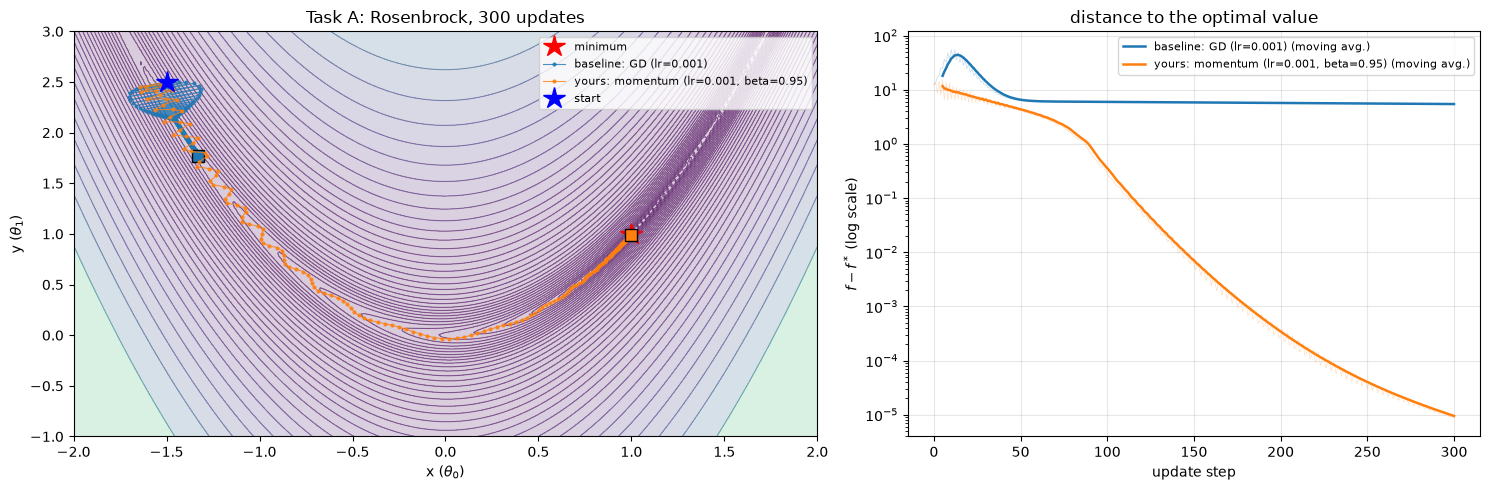

Task B  score = 1.32e-05   [TARGET MET]


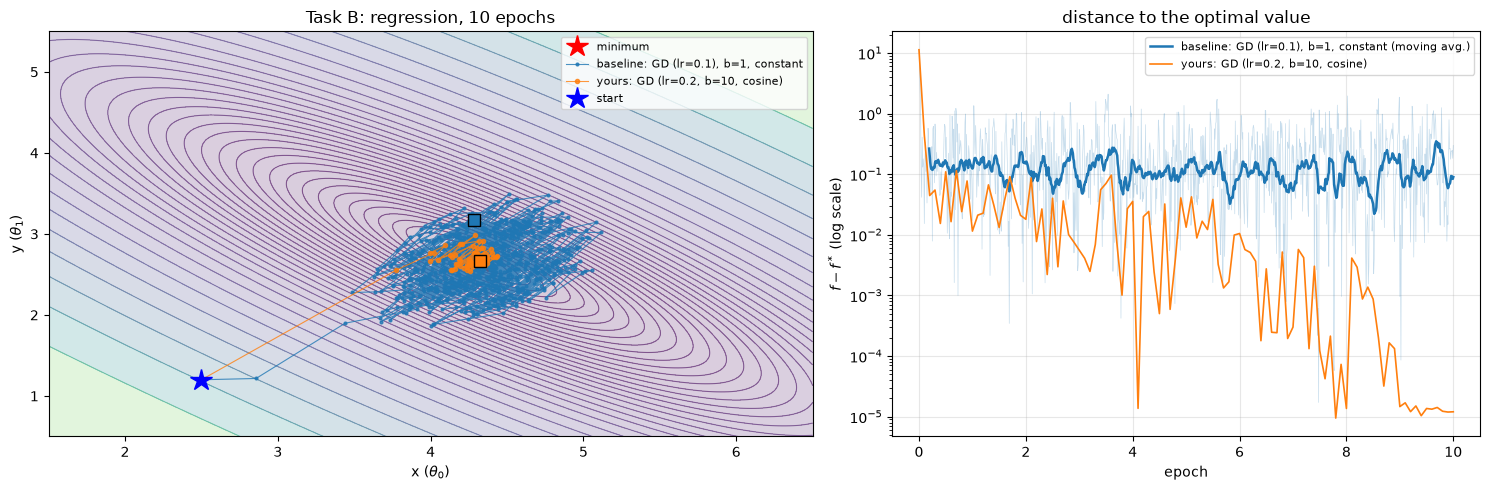

In [50]:
#@title Run the two fixed-budget tasks
OPTIMIZERS = {  # name -> (update function, state keys, required hyperparameters)
  'GD':       (GD_update,       [],          ['lr']),
  'momentum': (momentum_update, ['delta'],   ['lr', 'beta']),
  'nesterov': (nesterov_update, ['delta'],   ['lr', 'beta']),
  'adagrad':  (adagrad_update,  ['G'],       ['lr', 'eps']),
  'rmsprop':  (RMSProp_update,  ['v'],       ['lr', 'gamma', 'eps']),
  'adam':     (adam_update,     ['m', 'v'],  ['lr', 'beta1', 'beta2', 'eps']),
}
BUDGET_A, BUDGET_B_EPOCHS = 300, 10
TARGET_A, TARGET_B = 1e-2, 1e-3

def _get_optimizer(task):
  name = task['optimizer']
  if name not in OPTIMIZERS:
    raise ValueError(f"unknown optimizer {name!r}; choose one of {list(OPTIMIZERS)}")
  update, keys, required = OPTIMIZERS[name]
  missing = [k for k in required if k not in task['hyper_params']]
  if missing:
    raise ValueError(f"{name} needs the hyperparameters {missing}")
  return update, keys

def _label(task):
  hp = ', '.join(f'{k}={v}' for k, v in task['hyper_params'].items())
  extra = f", b={task['batch_size']}, {task['schedule']}" if 'batch_size' in task else ''
  return f"{task['optimizer']} ({hp}{extra})"

# ---------------- Task A ----------------
update, keys = _get_optimizer(task_a)
problem = get_problem('rosenbrock')
res_a = {
  'baseline: GD (lr=0.001)': run_optimizer(rosenbrock, GD_update, (-1.5, 2.5), {'lr': 0.001}, epochs=BUDGET_A),
  'yours: ' + _label(task_a): run_optimizer(rosenbrock, update, (-1.5, 2.5), task_a['hyper_params'],
                                            new_states(*keys), epochs=BUDGET_A),
}
traj, losses = res_a['yours: ' + _label(task_a)]
score_a = losses[-1] - problem[3] if len(traj) == BUDGET_A + 1 else float('inf')
print(f"Task A  score = {score_a:.2e}   " + ('[TARGET MET]' if score_a < TARGET_A else '[TARGET NOT MET]'))
plot_trajectories(problem, res_a, title=f'Task A: Rosenbrock, {BUDGET_A} updates', arrows=False)

# ---------------- Task B ----------------
update, keys = _get_optimizer(task_b)
bs = int(task_b['batch_size'])
assert 1 <= bs <= N, f'batch_size must be between 1 and {N}'
T = BUDGET_B_EPOCHS * math.ceil(N / bs)
base_lr = task_b['hyper_params']['lr']
problem = get_problem('regression')
res_b = {
  'baseline: GD (lr=0.1), b=1, constant': run_minibatch(GD_update, (2.5, 1.2), {'lr': 0.1}, batch_size=1, epochs=BUDGET_B_EPOCHS),
  'yours: ' + _label(task_b): run_minibatch(update, (2.5, 1.2), task_b['hyper_params'], new_states(*keys),
                                            batch_size=bs, epochs=BUDGET_B_EPOCHS,
                                            lr_schedule=lambda t: get_lr(t, T, base_lr, task_b['schedule'])),
}
traj, losses = res_b['yours: ' + _label(task_b)]
last = losses[-math.ceil(N / bs):] - reg_f_star
score_b = float(np.mean(last)) if np.all(np.isfinite(last)) else float('inf')
print(f"Task B  score = {score_b:.2e}   " + ('[TARGET MET]' if score_b < TARGET_B else '[TARGET NOT MET]'))
plot_trajectories(problem, res_b, title=f'Task B: regression, {BUDGET_B_EPOCHS} epochs',
                  updates_per_epoch={'baseline: GD (lr=0.1), b=1, constant': N, 'yours: ' + _label(task_b): math.ceil(N / bs)})

In [51]:
#@title Extra runs for Section 7 (how sensitive the choices are, and swapping the settings between tasks)
import contextlib, io

def _score_a(opt, hp):
  update, keys = OPTIMIZERS[opt][:2]
  with contextlib.redirect_stdout(io.StringIO()):
    tr_, ls_ = run_optimizer(rosenbrock, update, (-1.5, 2.5), hp, new_states(*keys), epochs=BUDGET_A)
  return ls_[-1] if len(tr_) == BUDGET_A + 1 else float('inf')

def _score_b(opt, hp, bs, sched, seed=0):
  update, keys = OPTIMIZERS[opt][:2]
  T_ = BUDGET_B_EPOCHS * math.ceil(N / bs)
  _, ls_ = run_minibatch(update, (2.5, 1.2), hp, new_states(*keys), batch_size=bs, epochs=BUDGET_B_EPOCHS,
                         seed=seed, lr_schedule=lambda t: get_lr(t, T_, hp['lr'], sched))
  last_ = ls_[-math.ceil(N / bs):] - reg_f_star
  return float(np.mean(last_)) if np.all(np.isfinite(last_)) else float('inf')

print('Task A, momentum: score for lr (rows) and beta = 0.9 / 0.93 / 0.95 / 0.97 / 0.99 (columns)')
for lr_ in [0.0005, 0.0008, 0.001, 0.0012, 0.0015]:
  print(f'  lr = {lr_:<7}' + ''.join(f'{_score_a("momentum", {"lr": lr_, "beta": b_}):10.1e}' for b_ in [0.9, 0.93, 0.95, 0.97, 0.99]))
for name, (opt, hp) in {'nesterov, lr=0.001, beta=0.9': ('nesterov', {'lr': 0.001, 'beta': 0.9}),
                        'adam, lr=0.03, betas=(0.9, 0.9)': ('adam', {'lr': 0.03, 'beta1': 0.9, 'beta2': 0.9, 'eps': 1e-8}),
                        'adam, lr=0.05, betas=(0.9, 0.999)': ('adam', {'lr': 0.05, 'beta1': 0.9, 'beta2': 0.999, 'eps': 1e-8}),
                        'rmsprop, lr=0.01, gamma=0.99': ('rmsprop', {'lr': 0.01, 'gamma': 0.99, 'eps': 1e-8}),
                        'adagrad, lr=0.5': ('adagrad', {'lr': 0.5, 'eps': 1e-10})}.items():
  print(f'  {name:34s} {_score_a(opt, hp):.1e}')

print('Task B, GD with b = 10')
print('  schedule (lr = 0.2):         ', {s: f'{_score_b("GD", {"lr": 0.2}, 10, s):.1e}' for s in ['constant', 'step', 'inverse', 'cosine']})
print('  base lr (cosine):            ', {lr_: f'{_score_b("GD", {"lr": lr_}, 10, "cosine"):.1e}' for lr_ in [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]})
print('  batch size (lr = 0.2, cosine):', {b_: f'{_score_b("GD", {"lr": 0.2}, b_, "cosine"):.1e}' for b_ in [1, 5, 10, 20, 50, 100]})
print('  other optimizers (cosine):   ', {
  'momentum lr=0.01 beta=0.5 b=1': f'{_score_b("momentum", {"lr": 0.01, "beta": 0.5}, 1, "cosine"):.1e}',
  'adam lr=0.3 b=5': f'{_score_b("adam", {"lr": 0.3, "beta1": 0.9, "beta2": 0.999, "eps": 1e-8}, 5, "cosine"):.1e}'})

seeds_ = [_score_b('GD', {'lr': 0.2}, 10, 'cosine', seed=sd) for sd in range(10)]
print(f'  my Task B settings with seeds 0-9: median {np.median(seeds_):.1e}, worst {max(seeds_):.1e}, '
      f'{sum(s < TARGET_B for s in seeds_)}/10 below the target')

print('Swapping the settings')
print(f'  Task A settings on Task B (momentum, lr=0.001, beta=0.95, b=10, constant): '
      f'{_score_b("momentum", {"lr": 0.001, "beta": 0.95}, 10, "constant"):.1e}')
with contextlib.redirect_stdout(io.StringIO()):
  tr_, _ = run_optimizer(rosenbrock, GD_update, (-1.5, 2.5), {'lr': 0.2}, epochs=BUDGET_A)
print(f'  Task B learning rate on Task A (GD, lr=0.2): diverged at update {len(tr_)}')

Task A, momentum: score for lr (rows) and beta = 0.9 / 0.93 / 0.95 / 0.97 / 0.99 (columns)


  lr = 0.0005    2.0e+00   2.3e-01   3.6e-02   3.3e-03   1.8e-01


  lr = 0.0008    1.4e-01   2.4e-02   1.3e-03   3.6e-03   3.5e-01


  lr = 0.001     5.2e-02   7.3e-03   8.7e-06   3.9e-03   3.8e-01


  lr = 0.0012    2.3e-02   2.2e-03   7.2e-05   1.4e-04   3.7e-01
  lr = 0.0015    3.2e-03       inf       inf       inf       inf
  nesterov, lr=0.001, beta=0.9       3.7e-04
  adam, lr=0.03, betas=(0.9, 0.9)    4.7e-05


  adam, lr=0.05, betas=(0.9, 0.999)  2.3e+00
  rmsprop, lr=0.01, gamma=0.99       4.9e+00
  adagrad, lr=0.5                    5.8e+00
Task B, GD with b = 10
  schedule (lr = 0.2):          {'constant': '2.7e-02', 'step': '1.6e-04', 'inverse': '3.0e-03', 'cosine': '1.3e-05'}


  base lr (cosine):             {0.05: '5.6e-03', 0.1: '8.7e-04', 0.2: '1.3e-05', 0.3: '3.6e-05', 0.4: '1.9e-04', 0.5: '8.4e-04', 0.6: '2.6e+03'}


  batch size (lr = 0.2, cosine): {1: '1.3e-03', 5: '1.4e-04', 10: '1.3e-05', 20: '8.2e-04', 50: '6.8e-03', 100: '1.5e-02'}


  other optimizers (cosine):    {'momentum lr=0.01 beta=0.5 b=1': '1.3e-05', 'adam lr=0.3 b=5': '1.1e-05'}
  my Task B settings with seeds 0-9: median 3.9e-05, worst 6.5e-04, 10/10 below the target
Swapping the settings
  Task A settings on Task B (momentum, lr=0.001, beta=0.95, b=10, constant): 5.3e-02
  Task B learning rate on Task A (GD, lr=0.2): diverged at update 2


> (a) Final settings and scores.
> (b) Why these optimizers and hyperparameters?
> (c) Which hyperparameter mattered most, and what happened when it was pushed too far?
> (d) Would the Task A settings also work for Task B, and the other way around?

**(a)**
| Task | Optimizer | Settings | Score | Target |
|---|---|---|---|---|
| A (Rosenbrock, 300 updates) | momentum | lr = 0.001, $\beta$ = 0.95 | $8.66\cdot10^{-6}$ | $10^{-2}$ |
| B (regression, 10 epochs) | GD | lr = 0.2, batch size 10, cosine schedule | $1.32\cdot10^{-5}$ | $10^{-3}$ |

**(b)** *Task A.* Rosenbrock is a long, curved, flat valley with steep walls: near the start the Hessian's eigenvalues are about 2000 across the valley and 0.2 along it. The walls limit a shared learning rate to roughly $2/2000$, and at such a rate plain GD crawls along the floor (the baseline stayed at 5.4). Section 3 showed that momentum builds up speed along the valley: with lr 0.0005, $\beta = 0.9$ reached $7.5\cdot10^{-3}$ in 1000 steps and $\beta = 0.99$ reached $10^{-3}$ in 363. With only 300 steps I needed more speed, so I doubled the learning rate to 0.001, close to the largest the walls allow, and used $\beta = 0.95$. This amplifies consistent gradients by up to 20 times without the long spiralling that $\beta = 0.99$ caused in Section 3. The per-parameter methods were worse here. Adagrad and RMSProp scored 5.8 and 4.9 with the settings in the table above, because they keep the huge gradients from the wall (Section 4), and Adam with the default betas and lr 0.05 got 2.3. Adam reached $4.7\cdot10^{-5}$ only after I lowered $\beta_2$ to 0.9 so that $\hat{\mathbf v}$ forgets the wall gradients quickly, and it needed more tuning than momentum.

*Task B.* The regression loss is mildly conditioned: its Hessian has eigenvalues 4.27 and 0.32, a condition number of about 13. Its difficulty is the noise of the per-sample gradients, so I chose the batch size and the schedule against that noise and kept plain GD. Section 6.2 showed that the noise variance falls as $1/b$, and Section 6.1 that $b = 10$ still gives many updates per epoch (100 updates in 10 epochs). Section 6.4 showed that cosine decay ends with the smallest rate and reaches the lowest final loss. The average rate of a cosine schedule is half its base rate, so I doubled the base rate from 0.1 to 0.2, which is still below the stability limit $2/4.27 = 0.47$. Momentum ($1.3\cdot10^{-5}$ at $b = 1$) and Adam ($1.1\cdot10^{-5}$ at $b = 5$) were no better, so I kept the simplest method. With other data orders the same settings stayed below the target for all 10 seeds I tried (median $3.9\cdot10^{-5}$, worst $6.5\cdot10^{-4}$).

**(c)** In Task A the learning rate mattered most. At $\beta = 0.95$, lr 0.0008 gave $1.3\cdot10^{-3}$, 0.001 gave $8.7\cdot10^{-6}$ and 0.0012 gave $7.2\cdot10^{-5}$. At 0.0015 the run diverged for every $\beta \ge 0.93$, because on walls with curvature about 2000 larger steps become unstable once momentum amplifies them. $\beta$ came second: 0.9 was too slow ($5.2\cdot10^{-2}$) and 0.99 spiralled (0.38).

In Task B the schedule mattered most. With the same lr and batch size, `constant` gave $2.7\cdot10^{-2}$, `inverse` $3.0\cdot10^{-3}$, `step` $1.6\cdot10^{-4}$ and `cosine` $1.3\cdot10^{-5}$. Pushing the learning rate too far broke the run: lr 0.5 still met the target ($8.4\cdot10^{-4}$), but lr 0.6 diverged (score $2.6\cdot10^3$). It is above the limit 0.47, and the cosine decay did not bring it below the limit before the steep direction blew up. The batch size had an optimum: $b = 1$ was too noisy ($1.3\cdot10^{-3}$), and $b = 100$ allowed only 10 updates ($1.5\cdot10^{-2}$).

**(d)** No. The two problems need learning rates about 200 times apart, because their curvatures differ that much (about 2000 on the Rosenbrock walls and 4.3 for the regression). The Task A settings on Task B (momentum, lr 0.001, $\beta$ 0.95, $b = 10$, constant schedule) scored $5.3\cdot10^{-2}$. Its steps are far too small for the regression, and after 10 epochs the parameters were still far from the minimum. The Task B learning rate on Task A (GD, lr 0.2) diverged at the second update. The batch size and schedule of Task B matter only when the gradients are noisy, and the high momentum of Task A is built for a long curved valley, which the regression loss does not have.

## 8. What each method is for

> 1. Which difficulty does each family of methods address: momentum methods, per-parameter (variance-normalized) methods, second-order methods, mini-batching, and learning-rate decay?
> 2. Adam was fast on several of these problems. When do its per-parameter learning rates help less?

**1.**
* **Momentum methods** address ill-conditioning in valleys. Averaging past gradients cancels the zig-zag across a narrow valley and builds up speed along its floor, and Nesterov's look-ahead reduces the overshoot.
* **Per-parameter (variance-normalized) methods** address parameters whose gradients have very different sizes. Each coordinate's step is divided by the typical size of its own gradient, which works well when steep and flat directions line up with the parameters, and lets the method keep moving through flat regions such as saddles.
* **Second-order methods** address ill-conditioning in any direction. The Hessian rescales and rotates the step, so a quadratic is solved in one step whatever its condition number or rotation, at a cost of $O(n^2)$ memory and $O(n^3)$ time per step, and with an attraction to saddle points.
* **Mini-batching** addresses the cost of exact gradients on large datasets. A mini-batch gives an unbiased gradient estimate whose variance falls as $1/b$, so we can make many cheap updates per epoch with noise we can control.
* **Learning-rate decay** addresses the noise floor of stochastic gradients. A large rate early gives fast progress, and a small rate late stops the parameters from jumping around the minimum.

**2.** Adam helps less when the badly conditioned directions are not aligned with the parameters. In Section 5.3, rotating the quadratic from 0° to 45° raised the number of steps Adam needed to reach $f < 10^{-3}$ from 57 to 122. GD with $\eta = 2/(1+\kappa)$ needed 63 at every angle. At 45° both coordinates mix the steep and the flat direction and see gradients of similar size, so dividing per coordinate cannot tell the directions apart, and Adam was slower than well-tuned plain GD. In a network this happens when the loss is badly conditioned along combinations of many weights (for example correlated input features of one layer) instead of along single weights.

I saw two more cases. On Rosenbrock (Task A) Adam with the default betas and lr 0.05 scored 2.3. With $\beta_2 = 0.999$, $\hat{\mathbf v}$ remembered the huge gradients from the wall for hundreds of steps and kept the steps small in the valley, much as Adagrad did in Section 4. On the noisy regression (Task B) Adam scored about the same as plain GD ($1.1\cdot10^{-5}$ against $1.3\cdot10^{-5}$), because there the difficulty was gradient noise, which the batch size and the learning-rate schedule handle.